Versão automazida, salvar arquivos na pasta sample

In [10]:
#1 fazer a coleta da telemetria do celular. ( não automatizado - via arquivo - adb no terminal)
import os
import re
import glob
import json
from datetime import datetime, timezone
from collections import defaultdict


def converter_duracao_segundos(duracao_str: str) -> int:
    """Converte strings de duração ('1:17:46' ou '05:11') para segundos."""
    partes = [int(p) for p in duracao_str.strip().split(":")]
    if len(partes) == 3:
        return partes[0] * 3600 + partes[1] * 60 + partes[2]
    elif len(partes) == 2:
        return partes[0] * 60 + partes[1]
    return int(partes[0])


def extrair_data_referencia(raw_text: str, caminho_arquivo: str) -> str:
    """Identifica a data de referência (YYYY-MM-DD) do dump Android."""
    range_match = re.search(r'timeRange="[^"]*?(\d{2})/(\d{2})/(\d{4})[^"]*"', raw_text)
    if range_match:
        todas_datas = re.findall(r'(\d{2})/(\d{2})/(\d{4})', range_match.group(0))
        if todas_datas:
            dia, mes, ano = todas_datas[-1]
            return f"{ano}-{mes}-{dia}"

    eventos_ts = re.findall(r'time="(\d{4}-\d{2}-\d{2})\s+\d{2}:\d{2}:\d{2}"', raw_text)
    if eventos_ts:
        return eventos_ts[-1]

    nome_match = re.search(r'(\d{4}-\d{2}-\d{2})', os.path.basename(caminho_arquivo))
    if nome_match:
        return nome_match.group(1)

    return datetime.now().strftime("%Y-%m-%d")


def processar_arquivo_telemetria(caminho_arquivo: str) -> dict:
    """Faz o parse completo de um dump ADB e retorna o dicionário estruturado."""
    with open(caminho_arquivo, "r", encoding="utf-8", errors="ignore") as f:
        raw_text = f.read()

    data_ref = extrair_data_referencia(raw_text, caminho_arquivo)
    range_match = re.search(r'timeRange="([^"]+)"', raw_text)
    time_range = range_match.group(1) if range_match else "Não identificado"

    # Parse da tabela 'In-memory daily stats'
    apps_usados = []
    if "In-memory daily stats" in raw_text and "packages" in raw_text:
        bloco = raw_text.split("In-memory daily stats", 1)[1].split("packages", 1)[1]
        for linha in bloco.splitlines():
            s = linha.strip()
            if not s.startswith("package="):
                if apps_usados:
                    break
                continue

            m_pkg = re.search(r"package=([^\s]+)", s)
            m_used = re.search(r'totalTimeUsed="([^"]+)"', s)
            m_fs = re.search(r'totalTimeFS="([^"]+)"', s)
            m_cnt = re.search(r"appLaunchCount=(\d+)", s)

            if m_pkg and m_used:
                pkg = m_pkg.group(1)
                sec_fg = converter_duracao_segundos(m_used.group(1))
                sec_fs = converter_duracao_segundos(m_fs.group(1)) if m_fs else 0
                launches = int(m_cnt.group(1)) if m_cnt else 0

                if sec_fg > 0 or sec_fs > 0:
                    apps_usados.append({
                        "package": pkg,
                        "foreground_str": m_used.group(1),
                        "foreground_minutes": round(sec_fg / 60, 2),
                        "fg_service_str": m_fs.group(1) if m_fs else "00:00",
                        "fg_service_minutes": round(sec_fs / 60, 2),
                        "launch_count": launches
                    })

    apps_usados.sort(key=lambda x: x["foreground_minutes"], reverse=True)

    # Parse dos eventos cronológicos ('Last 24 hour events')
    event_pattern = re.compile(r'time="([^"]+)"\s+type=([A-Z_]+)\s+package=([^\s]+)')
    desbloqueios = 0
    notificacoes = defaultdict(int)
    segundos_noturno = 0.0
    sessoes_ativas = {}

    for linha in raw_text.splitlines():
        m = event_pattern.search(linha)
        if not m:
            continue
        ts_str, ev_type, pkg = m.groups()
        dt = datetime.strptime(ts_str, "%Y-%m-%d %H:%M:%S")

        if ev_type == "KEYGUARD_HIDDEN":
            desbloqueios += 1
        elif ev_type == "NOTIFICATION_INTERRUPTION":
            notificacoes[pkg] += 1
        elif ev_type == "ACTIVITY_RESUMED":
            sessoes_ativas[pkg] = dt
        elif ev_type in ("ACTIVITY_PAUSED", "ACTIVITY_STOPPED", "SCREEN_NON_INTERACTIVE"):
            alvos = list(sessoes_ativas.keys()) if ev_type == "SCREEN_NON_INTERACTIVE" else ([pkg] if pkg in sessoes_ativas else [])
            for p in alvos:
                start_dt = sessoes_ativas.pop(p)
                dur = (dt - start_dt).total_seconds()
                if 0 < dur < 7200 and 19 <= start_dt.hour <= 23 and p not in ("com.sec.android.app.launcher", "com.android.settings"):
                    segundos_noturno += dur

    apps_trabalho_sistema = {
        "com.ubercab.driver", "co.gigu.app", "com.android.settings",
        "com.sec.android.app.launcher", "com.google.android.permissioncontroller",
        "com.android.systemui"
    }
    tela_total_min = round(sum(a["foreground_minutes"] for a in apps_usados), 2)
    uso_pessoal_min = round(sum(a["foreground_minutes"] for a in apps_usados if a["package"] not in apps_trabalho_sistema), 2)
    top_notif = sorted(notificacoes.items(), key=lambda x: x[1], reverse=True)[:5]

    return {
        "reference_date": data_ref,
        "collected_at": datetime.now(timezone.utc).isoformat(),
        "source_info": {
            "mode": "adb_file_dump",
            "source_file": caminho_arquivo,
            "time_range": time_range
        },
        "summary": {
            "total_screen_minutes": tela_total_min,
            "total_leisure_screen_minutes": uso_pessoal_min,
            "night_window_19h_23h_minutes": round(segundos_noturno / 60, 2),
            "unlock_count": desbloqueios,
            "total_notifications": sum(notificacoes.values()),
            "top_notification_sources": [{"package": k, "count": v} for k, v in top_notif]
        },
        "apps_ranked": apps_usados
    }


def executar_etapa_1_telemetria(pasta_saida: str = "/content/historico_telemetria"):
    """
    Varre '/content/sample_data' e '/content' em busca de todos os dumps .txt,
    mantém exatamente o mesmo print de dados por app da versão anterior para cada dia
    e salva os arquivos JSON organizados por data.
    """
    arquivos_encontrados = []
    for pasta in ["/content/sample_data", "/content", "sample_data", "."]:
        if os.path.isdir(pasta):
            for arq in sorted(glob.glob(os.path.join(pasta, "*.txt"))):
                if os.path.basename(arq) != "README.md" and arq not in arquivos_encontrados:
                    if os.path.basename(arq) not in [os.path.basename(x) for x in arquivos_encontrados]:
                        arquivos_encontrados.append(arq)

    if not arquivos_encontrados:
        raise FileNotFoundError("Nenhum arquivo .txt encontrado em /content/sample_data/ ou /content/.")

    os.makedirs(pasta_saida, exist_ok=True)
    historico = []

    for caminho in arquivos_encontrados:
        dados = processar_arquivo_telemetria(caminho)
        data_ref = dados["reference_date"]
        resumo = dados["summary"]

        arquivo_json = os.path.join(pasta_saida, f"telemetria_{data_ref}.json")
        with open(arquivo_json, "w", encoding="utf-8") as f:
            json.dump(dados, f, indent=2, ensure_ascii=False)

        historico.append(dados)

        # Print idêntico ao formato exato da versão anterior para cada dia processado
        print("=================================================================")
        print(f"   #1 TELEMETRIA DO CELULAR COLETADA VIA ARQUIVO ({data_ref})    ")
        print("=================================================================")
        print(f"Arquivo lido:      {caminho}")
        print(f"Janela analisada:  {dados['source_info']['time_range']}")
        print(f"Tela Total (Fg):   {resumo['total_screen_minutes']} min")
        print(f"Uso Pessoal/Lazer: {resumo['total_leisure_screen_minutes']} min (excluindo trabalho/sistema)")
        print(f"Janela Noturna:    {resumo['night_window_19h_23h_minutes']} min (19h às 23h)")
        print(f"Desbloqueios:      {resumo['unlock_count']} (KEYGUARD_HIDDEN)")
        print(f"Notificações:      {resumo['total_notifications']} interrupções")

        print("\n--- Top Aplicativos por Tempo em Primeiro Plano ---")
        for idx, app in enumerate(dados["apps_ranked"], start=1):
            if app["foreground_minutes"] > 0:
                print(f"  {idx:02d}. {app['package']:<40} | {app['foreground_str']:<8} ({app['foreground_minutes']:6.2f} min) | Aberturas: {app['launch_count']}")

        print(f"\n[OK] Dados salvos por data em: {arquivo_json}\n")

    return historico


# Executa a Etapa #1
dados_telemetria_por_dia = executar_etapa_1_telemetria()

   #1 TELEMETRIA DO CELULAR COLETADA VIA ARQUIVO (2026-11-23)    
Arquivo lido:      /content/usagestats_dump-23-11.txt
Janela analisada:  22/11/2026, 18:04 – 23/11/2026, 18:04
Tela Total (Fg):   276.63 min
Uso Pessoal/Lazer: 128.78 min (excluindo trabalho/sistema)
Janela Noturna:    81.0 min (19h às 23h)
Desbloqueios:      23 (KEYGUARD_HIDDEN)
Notificações:      115 interrupções

--- Top Aplicativos por Tempo em Primeiro Plano ---
  01. com.ubercab.driver                       | 2:09:35  (129.58 min) | Aberturas: 2
  02. com.google.android.youtube               | 1:17:46  ( 77.77 min) | Aberturas: 4
  03. com.android.settings                     | 12:55    ( 12.92 min) | Aberturas: 3
  04. com.android.chrome                       | 12:28    ( 12.47 min) | Aberturas: 5
  05. com.google.android.apps.photos           | 06:51    (  6.85 min) | Aberturas: 5
  06. com.mercadolibre                         | 05:52    (  5.87 min) | Aberturas: 6
  07. com.google.android.gm                    |

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
#2 fazer check in com usuário - pergunta relacionadas a hiegene do sono, atividade fisica e metas
import os
import re
import json
from datetime import datetime, timezone


def etapa_2_checkin_usuario(
    pasta_saida: str = "/content/historico_checkins",
    data_referencia: str = None
) -> dict:
    """
    ETAPA #2 (Isolada — Agente Conversacional):
    Pergunta inicialmente o nome do usuário (sem valores hardcoded),
    gera um user_id dinâmico baseado no nome informado e conduz o check-in
    em 08 perguntas curtas (uma por vez), salvando o Contrato 1A por data
    apenas após confirmação explícita.
    """
    print("=================================================================")
    print("   ETAPA #2 — CHECK-IN INTERATIVO (AGENTE CONVERSACIONAL)        ")
    print("=================================================================")
    print("Bem-vindo ao FluIA! Antes de começarmos, qual é o seu nome?\n")

    # Pergunta inicial obrigatória: Nome do usuário
    while True:
        nome_usuario = input("Digite seu nome: ").strip()
        if nome_usuario:
            break
        print("⚠️ Por favor, informe seu nome para iniciarmos o check-in.\n")

    # Gera um identificador normalizado a partir do nome informado
    slug_nome = re.sub(r"[^a-z0-9]+", "_", nome_usuario.lower()).strip("_") or "usuario"
    user_id = f"usr_{slug_nome}_01"

    print(f"\nOlá, {nome_usuario}! Vamos fazer seu check-in rápido em 8 perguntas curtas.")
    print("Digite sua resposta e pressione ENTER para ir para a próxima.\n")

    def perguntar_texto(numero: int, categoria: str, enunciado: str) -> str:
        while True:
            resp = input(f"[{numero}/8 — {categoria}]\n{enunciado}\n-> ").strip()
            if resp:
                print("-" * 65)
                return resp
            print("⚠️ Por favor, digite uma resposta antes de avançar.\n")

    # --- BLOCO 1: HIGIENE DO SONO (Perguntas 1 e 2) ---
    p1_horario_telas = perguntar_texto(
        1, "Higiene do Sono",
        "A que horas você largou ou bloqueou o celular ontem à noite antes de dormir?"
    )

    p2_qualidade_sono = perguntar_texto(
        2, "Higiene do Sono",
        "Como foi a qualidade do seu sono (demorou para adormecer, acordou no meio da noite ou acordou disposto)?"
    )

    # --- BLOCO 2: ATIVIDADE FÍSICA (Perguntas 3 e 4) ---
    p3_exercicio_hoje = perguntar_texto(
        3, "Atividade Física",
        "Você realizou alguma caminhada, alongamento ou exercício físico hoje? Se sim, qual e por quanto tempo?"
    )

    p4_tempo_sentado = perguntar_texto(
        4, "Atividade Física",
        "Passou muitas horas contínuas sentado ou dirigindo hoje sem pausas ativas?"
    )

    # --- BLOCO 3: METAS, ENERGIA E HUMOR (Perguntas 5, 6 e 7) ---
    p5_progresso_metas = perguntar_texto(
        5, "Metas de Bem-Estar",
        "Como você avalia o seu progresso hoje na meta de reduzir o uso noturno de telas?"
    )

    while True:
        p6_txt = input(
            "[6/8 — Nível de Energia]\n"
            "De 1 a 5 (1 = esgotado, 5 = muito disposto), qual é o seu nível de energia agora?\n-> "
        ).strip()
        if p6_txt.isdigit() and 1 <= int(p6_txt) <= 5:
            p6_energia = int(p6_txt)
            print("-" * 65)
            break
        print("⚠️ Digite apenas um número inteiro entre 1 e 5.\n")

    p7_humor = perguntar_texto(
        7, "Estado Emocional / Humor",
        "Em uma palavra, como você descreve o seu humor neste momento (ex.: disposto, cansado, focado, estressado)?"
    )

    # --- BLOCO 4: TRIAGEM DE SEGURANÇA — CHUNK 87 (Pergunta 8) ---
    while True:
        p8_txt = input(
            "[8/8 — Triagem de Bem-Estar Emocional]\n"
            "Nos últimos dias, você tem sentido tristeza, ansiedade ou esgotamento intenso e persistente? (sim/não)\n-> "
        ).strip().lower()
        if p8_txt in ("sim", "s", "não", "nao", "n"):
            p8_distress = p8_txt in ("sim", "s")
            print("-" * 65)
            break
        print("⚠️ Responda apenas com 'sim' ou 'não'.\n")

    agora = datetime.now(timezone.utc)
    data_str = data_referencia or datetime.now().strftime("%Y-%m-%d")

    print("\n=================================================================")
    print(f"   RESUMO DO CHECK-IN — {nome_usuario.upper()} ({data_str})")
    print("=================================================================")
    print(f"• Usuário:                     {nome_usuario} (ID: {user_id})")
    print(f"1. Horário que largou telas:   {p1_horario_telas}")
    print(f"2. Qualidade do sono:          {p2_qualidade_sono}")
    print(f"3. Exercício/caminhada hoje:   {p3_exercicio_hoje}")
    print(f"4. Tempo sentado/dirigindo:    {p4_tempo_sentado}")
    print(f"5. Progresso nas metas:        {p5_progresso_metas}")
    print(f"6. Nível de energia:           {p6_energia}/5")
    print(f"7. Humor atual:                {p7_humor}")
    print(f"8. Sofrimento persistente:     {'Sim' if p8_distress else 'Não'}")
    print("=================================================================")

    confirmar = input("\nDeseja confirmar e salvar o check-in desta data? (sim/não): ").strip().lower()
    if confirmar not in ("sim", "s", ""):
        print("❌ Operação cancelada. Nenhum arquivo foi salvo.")
        return {}

    # Contrato 1A estrito (v1.1) com nome e user_id capturados dinamicamente
    contract_1a = {
        "contract_version": "1.1",
        "event_type": "daily_checkin",
        "reference_date": data_str,
        "timestamp": agora.isoformat(),
        "user_id": user_id,
        "user_data": {
            "profile": {
                "name": nome_usuario,
                "preferences": {
                    "notification_window": "19:00-22:00",
                    "communication_tone": "empatico",
                    "do_not_disturb_weekends": True
                },
                "accessibility_or_work_needs": {
                    "needs_color_screen": False,
                    "needs_phone_reachable_for_care_or_work": True,
                    "bedtime_target": "22:30"
                }
            },
            "goals": [
                {
                    "goal_id": "goal_sono_01",
                    "description": "Reduzir o uso recreativo de telas após as 21h00 para melhorar a higiene do sono",
                    "target_frequency": "diario"
                },
                {
                    "goal_id": "goal_atv_02",
                    "description": "Realizar ao menos 20 minutos de caminhada ou alongamento ativo nos dias de trabalho",
                    "target_frequency": "diario"
                }
            ],
            "checkin_payload": {
                "mood": p7_humor,
                "energy_level": p6_energia,
                "persistent_emotional_distress": p8_distress,
                "structured_answers": {
                    "q1_bedtime_screen_cutoff": p1_horario_telas,
                    "q2_sleep_quality": p2_qualidade_sono,
                    "q3_physical_activity": p3_exercicio_hoje,
                    "q4_sedentary_driving_time": p4_tempo_sentado,
                    "q5_goals_progress": p5_progresso_metas,
                    "q6_energy_level": p6_energia,
                    "q7_mood": p7_humor,
                    "q8_persistent_emotional_distress": p8_distress
                },
                "free_text_notes": (
                    f"Sono (telas): {p1_horario_telas} | Qualidade: {p2_qualidade_sono} | "
                    f"Atividade: {p3_exercicio_hoje} | Sedentarismo: {p4_tempo_sentado} | "
                    f"Metas: {p5_progresso_metas}"
                )
            },
            "feedback_payload": None
        }
    }

    os.makedirs(pasta_saida, exist_ok=True)
    arquivo_data = os.path.join(pasta_saida, f"checkin_contract_1a_{data_str}.json")
    with open(arquivo_data, "w", encoding="utf-8") as f:
        json.dump(contract_1a, f, indent=2, ensure_ascii=False)

    print(f"\n✅ Etapa #2 concluída! Check-in salvo por data em: '{arquivo_data}'")
    return contract_1a


if __name__ == "__main__":
    etapa_2_checkin_usuario()

   ETAPA #2 — CHECK-IN INTERATIVO (AGENTE CONVERSACIONAL)        
Bem-vindo ao FluIA! Antes de começarmos, qual é o seu nome?

Digite seu nome: higor

Olá, higor! Vamos fazer seu check-in rápido em 8 perguntas curtas.
Digite sua resposta e pressione ENTER para ir para a próxima.

[1/8 — Higiene do Sono]
A que horas você largou ou bloqueou o celular ontem à noite antes de dormir?
-> 22
-----------------------------------------------------------------
[2/8 — Higiene do Sono]
Como foi a qualidade do seu sono (demorou para adormecer, acordou no meio da noite ou acordou disposto)?
-> acordei disposto
-----------------------------------------------------------------
[3/8 — Atividade Física]
Você realizou alguma caminhada, alongamento ou exercício físico hoje? Se sim, qual e por quanto tempo?
-> sim 1 hora
-----------------------------------------------------------------
[4/8 — Atividade Física]
Passou muitas horas contínuas sentado ou dirigindo hoje sem pausas ativas?
-> sim 2 horas
--------

In [13]:
#3 Agente Chat
# Ler e salvar dados de entradas etapas 1 e 2
# Apresentar sugestões validadas ao usuario
# Registrar o feedback do utilizador
# Não pode Ler logs brutos de telemetria - fazer parse
# Não pode iniciar fluxos proativos por conta própria (apenas encaminha o que foi validado).
# Não pode consultar a base de conhecimento (RAG).
# Não pode gerar diagnósticos ou sugestões.
# Consulta a Base de perfil (Perfil, Metas, Config)(Leitura / Escrita via Tool)

import os
import glob
import json
from datetime import datetime, timezone
from typing import Optional, Dict, Any


class BasePerfilTool:
    """
    Tool de Leitura e Escrita na Base de Perfil (Perfil, Metas, Config)
    permitida exclusivamente ao Agente Chat conforme a matriz PoLP.
    Sincroniza dinamicamente o nome e o user_id recebidos da Etapa #2 (Check-in).
    """
    def __init__(self, caminho_perfil: str = "/content/base_perfil_usuario.json"):
        self.caminho_perfil = caminho_perfil
        self._garantir_perfil_inicial()

    def _garantir_perfil_inicial(self):
        if not os.path.exists(self.caminho_perfil):
            perfil_padrao = {
                "user_id": "usr_padrao_01",
                "profile": {
                    "name": "Usuário",
                    "preferences": {
                        "notification_window": "19:00-22:00",
                        "communication_tone": "empatico",
                        "do_not_disturb_weekends": True
                    },
                    "accessibility_or_work_needs": {
                        "needs_color_screen": False,
                        "needs_phone_reachable_for_care_or_work": True,
                        "bedtime_target": "22:30"
                    }
                },
                "goals": [
                    {
                        "goal_id": "goal_sono_01",
                        "description": "Reduzir o uso recreativo de telas após as 21h00 para melhorar a higiene do sono",
                        "target_frequency": "diario"
                    },
                    {
                        "goal_id": "goal_atv_02",
                        "description": "Realizar ao menos 20 minutos de caminhada ou alongamento ativo nos dias de trabalho",
                        "target_frequency": "diario"
                    }
                ],
                "updated_at": datetime.now(timezone.utc).isoformat()
            }
            os.makedirs(os.path.dirname(self.caminho_perfil) or ".", exist_ok=True)
            with open(self.caminho_perfil, "w", encoding="utf-8") as f:
                json.dump(perfil_padrao, f, indent=2, ensure_ascii=False)

    def ler_perfil(self) -> Dict[str, Any]:
        """Leitura da Base de Perfil (Perfil, Metas, Config)."""
        with open(self.caminho_perfil, "r", encoding="utf-8") as f:
            return json.load(f)

    def sincronizar_identidade_usuario(self, user_id: str, nome: str) -> Dict[str, Any]:
        """Atualiza dinamicamente o nome e o user_id na Base de Perfil a partir da Etapa #2."""
        dados = self.ler_perfil()
        alterado = False

        if user_id and dados.get("user_id") != user_id:
            dados["user_id"] = user_id
            alterado = True

        if nome and dados.get("profile", {}).get("name") != nome:
            dados["profile"]["name"] = nome
            alterado = True

        if alterado:
            dados["updated_at"] = datetime.now(timezone.utc).isoformat()
            with open(self.caminho_perfil, "w", encoding="utf-8") as f:
                json.dump(dados, f, indent=2, ensure_ascii=False)

        return dados

    def atualizar_perfil(
        self,
        novas_preferencias: Optional[dict] = None,
        novas_metas: Optional[list] = None,
        novo_nome: Optional[str] = None
    ) -> Dict[str, Any]:
        """Escrita controlada na Base de Perfil (Perfil, Metas, Config)."""
        dados = self.ler_perfil()
        if novo_nome:
            dados["profile"]["name"] = novo_nome
        if novas_preferencias:
            dados["profile"]["preferences"].update(novas_preferencias)
        if novas_metas is not None:
            dados["goals"] = novas_metas
        dados["updated_at"] = datetime.now(timezone.utc).isoformat()
        with open(self.caminho_perfil, "w", encoding="utf-8") as f:
            json.dump(dados, f, indent=2, ensure_ascii=False)
        return dados


class AgenteChatFluIA:
    """
    ETAPA #3 — AGENTE CHAT (Interface Conversacional & Orquestrador de Entrada/Saída)
    =================================================================================
    PERMISSÕES (PoLP):
      [OK] Ler arquivos já processados das Etapas #1 e #2 (JSONs estruturados)
      [OK] Consultar e atualizar a Base de Perfil (incluindo nome e user_id dinâmicos) via Tool
      [OK] Consolidar o pacote de entrada (Contrato 1A + Telemetria Estruturada)
      [OK] Apresentar sugestões JÁ VALIDADAS pelo Agente de Ação ao usuário
      [OK] Registrar o feedback do utilizador (Contrato 1B -> Analista)

    RESTRIÇÕES ESTRITAS (BLOQUEADAS):
      [X] NÃO lê logs brutos (.txt) nem faz parse de dumps ADB
      [X] NÃO inicia fluxos proativos por conta própria
      [X] NÃO consulta a base de conhecimento científica (RAG)
      [X] NÃO gera diagnósticos clínicos nem inventa sugestões
    """

    def __init__(
        self,
        pasta_telemetria: str = "/content/historico_telemetria",
        pasta_checkins: str = "/content/historico_checkins",
        pasta_contratos_chat: str = "/content/contratos_chat",
        caminho_perfil: str = "/content/base_perfil_usuario.json"
    ):
        self.pasta_telemetria = pasta_telemetria
        self.pasta_checkins = pasta_checkins
        self.pasta_contratos_chat = pasta_contratos_chat
        self.perfil_tool = BasePerfilTool(caminho_perfil)
        os.makedirs(self.pasta_contratos_chat, exist_ok=True)

    def _validar_nao_eh_log_bruto(self, caminho: str):
        """Guardrail PoLP: impede leitura de arquivos .txt brutos ou dumps ADB."""
        if not caminho.endswith(".json"):
            raise PermissionError(
                f"[VIOLAÇÃO PoLP] O Agente Chat não tem permissão para ler logs brutos ({caminho}). "
                "Apenas JSONs já processados pelas Etapas #1 e #2 são aceitos."
            )

    def _buscar_arquivo_mais_recente(self, pasta: str, padrao: str) -> Optional[str]:
        if not os.path.isdir(pasta):
            return None
        arquivos = sorted(glob.glob(os.path.join(pasta, padrao)))
        return arquivos[-1] if arquivos else None

    def ler_e_consolidar_entradas_etapas_1_e_2(self, data_referencia: Optional[str] = None) -> Dict[str, Any]:
        """
        1. Lê o JSON da Etapa #2 (Check-in) para obter o nome e user_id informados pelo usuário.
        2. Sincroniza esse nome/user_id na Base de Perfil via Tool (sem valores hardcoded).
        3. Lê o JSON da Etapa #1 (Telemetria) da mesma data.
        4. Salva o pacote consolidado para o Agente Analista (Etapa #4).
        """
        # Localiza arquivo da Etapa #2 (Check-in)
        if data_referencia:
            arq_checkin = os.path.join(self.pasta_checkins, f"checkin_contract_1a_{data_referencia}.json")
        else:
            arq_checkin = self._buscar_arquivo_mais_recente(self.pasta_checkins, "checkin_contract_1a_*.json")

        if not arq_checkin or not os.path.exists(arq_checkin):
            raise FileNotFoundError(
                "Nenhum arquivo JSON da Etapa #2 encontrado. Execute a Etapa #2 antes do Agente Chat."
            )
        self._validar_nao_eh_log_bruto(arq_checkin)

        with open(arq_checkin, "r", encoding="utf-8") as f:
            dados_checkin = json.load(f)

        # Extrai dinamicamente o nome e o user_id respondidos no check-in da Etapa #2
        user_id_dinamico = dados_checkin.get("user_id", "usr_padrao_01")
        nome_dinamico = (
            dados_checkin.get("user_data", {})
            .get("profile", {})
            .get("name", "Usuário")
        )

        # Sincroniza a Base de Perfil via Tool com o nome dinâmico do usuário
        perfil_base = self.perfil_tool.sincronizar_identidade_usuario(
            user_id=user_id_dinamico,
            nome=nome_dinamico
        )

        data_ref = dados_checkin.get("reference_date", datetime.now().strftime("%Y-%m-%d"))

        # Localiza arquivo da Etapa #1 (Telemetria já parseada em JSON)
        arq_telemetria = os.path.join(self.pasta_telemetria, f"telemetria_{data_ref}.json")
        if not os.path.exists(arq_telemetria):
            arq_telemetria = self._buscar_arquivo_mais_recente(self.pasta_telemetria, "telemetria_*.json")

        dados_telemetria = {}
        if arq_telemetria and os.path.exists(arq_telemetria):
            self._validar_nao_eh_log_bruto(arq_telemetria)
            with open(arq_telemetria, "r", encoding="utf-8") as f:
                dados_telemetria = json.load(f)

        # Consolida Contrato 1A enriquecido com a Base de Perfil atualizada e o resumo da Etapa #1
        pacote_consolidado = {
            "contract_version": "1.1",
            "event_type": "chat_consolidated_input",
            "reference_date": data_ref,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "user_id": perfil_base["user_id"],
            "user_data": {
                "profile": perfil_base["profile"],
                "goals": perfil_base["goals"],
                "checkin_payload": dados_checkin["user_data"]["checkin_payload"],
                "telemetry_summary_ref": dados_telemetria.get("summary", {}),
                "telemetry_reference_date": dados_telemetria.get("reference_date", None)
            }
        }

        caminho_saida = os.path.join(self.pasta_contratos_chat, f"chat_input_consolidado_{data_ref}.json")
        with open(caminho_saida, "w", encoding="utf-8") as f:
            json.dump(pacote_consolidado, f, indent=2, ensure_ascii=False)

        print("=================================================================")
        print("   #3 AGENTE CHAT — LEITURA E CONSOLIDAÇÃO (ETAPAS #1 + #2)      ")
        print("=================================================================")
        print(f"• Usuário sincronizado:       {perfil_base['profile']['name']} (ID: {perfil_base['user_id']})")
        print(f"• Meta de sono na Base:       {perfil_base['profile']['accessibility_or_work_needs']['bedtime_target']}")
        print(f"• Etapa #2 (Check-in) lida:   {os.path.basename(arq_checkin)}")
        print(f"• Etapa #1 (Telemetria) lida: {os.path.basename(arq_telemetria) if arq_telemetria else 'Não encontrada'}")
        print(f"✅ Pacote consolidado salvo em: '{caminho_saida}'\n")

        return pacote_consolidado

    def apresentar_sugestoes_validadas_e_registrar_feedback(
        self,
        contrato_acao_validado: Dict[str, Any],
        interativo: bool = True
    ) -> Optional[Dict[str, Any]]:
        """
        Recebe o contrato JÁ VALIDADO pelo Agente Analista/Juiz (Contrato 4):
        - Se status != 'ready_to_deliver': respeita o silêncio intencional.
        - Se houver mensagem validada: apresenta ao usuário usando seu nome dinâmico e coleta feedback (Contrato 1B).
        """
        perfil_atual = self.perfil_tool.ler_perfil()
        nome_usuario = perfil_atual.get("profile", {}).get("name", "Usuário")
        user_id_atual = perfil_atual.get("user_id", "usr_padrao_01")

        status = contrato_acao_validado.get("delivery_status", "silent_no_action")
        mensagem_validada = contrato_acao_validado.get("validated_user_message")
        intervention_id = contrato_acao_validado.get("intervention_id", "int_none")

        print("=================================================================")
        print("   #3 AGENTE CHAT — ENTREGA DE SUGESTÃO VALIDADA & FEEDBACK      ")
        print("=================================================================")

        # Guardrail: Não pode iniciar fluxos proativos por conta própria
        if status != "ready_to_deliver" or not mensagem_validada:
            print(f"🔇 Silêncio intencional respeitado para {nome_usuario}.")
            print("   O Agente Chat não iniciará conversa proativa por conta própria.")
            return None

        # Apresenta estritamente a sugestão validada (sem alterar ou diagnosticar)
        print(f"\n💬 Mensagem Validada para {nome_usuario}:\n\"{mensagem_validada}\"\n")
        print("-" * 65)

        if interativo:
            while True:
                util_txt = input(f"{nome_usuario}, esta sugestão foi útil para você agora? (sim/não): ").strip().lower()
                if util_txt in ("sim", "s", "não", "nao", "n"):
                    was_helpful = util_txt in ("sim", "s")
                    break
                print("⚠️ Responda apenas com 'sim' ou 'não'.")

            while True:
                rating_txt = input("De 1 a 5, qual nota você dá para esta recomendação? (1-5): ").strip()
                if rating_txt.isdigit() and 1 <= int(rating_txt) <= 5:
                    rating = int(rating_txt)
                    break
                print("⚠️ Digite um número inteiro de 1 a 5.")

            comentario = input("Gostaria de deixar algum comentário ou ajuste para suas metas? (opcional): ").strip()
        else:
            was_helpful = True
            rating = 5
            comentario = "Sugestão clara e respeitando minhas restrições."

        # Gera Contrato 1B (Feedback do Usuário -> Agente Analista) com user_id dinâmico
        data_str = contrato_acao_validado.get("reference_date", datetime.now().strftime("%Y-%m-%d"))
        contract_1b = {
            "contract_version": "1.1",
            "event_type": "user_feedback",
            "reference_date": data_str,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "user_id": user_id_atual,
            "user_name": nome_usuario,
            "feedback_payload": {
                "intervention_id": intervention_id,
                "was_helpful": was_helpful,
                "rating": rating,
                "user_comment": comentario
            }
        }

        caminho_fb = os.path.join(self.pasta_contratos_chat, f"feedback_contract_1b_{data_str}.json")
        with open(caminho_fb, "w", encoding="utf-8") as f:
            json.dump(contract_1b, f, indent=2, ensure_ascii=False)

        print(f"\n✅ Feedback de {nome_usuario} registrado no Contrato 1B: '{caminho_fb}'")
        return contract_1b


# =====================================================================
# EXECUÇÃO DA ETAPA #3 (AGENTE CHAT)
# =====================================================================
if __name__ == "__main__":
    agente_chat = AgenteChatFluIA()

    try:
        entrada_consolidada = agente_chat.ler_e_consolidar_entradas_etapas_1_e_2()
    except FileNotFoundError as e:
        print(f"[Info] {e}")


   #3 AGENTE CHAT — LEITURA E CONSOLIDAÇÃO (ETAPAS #1 + #2)      
• Usuário sincronizado:       higor (ID: usr_higor_01)
• Meta de sono na Base:       22:30
• Etapa #2 (Check-in) lida:   checkin_contract_1a_2026-11-24.json
• Etapa #1 (Telemetria) lida: telemetria_2026-11-24.json
✅ Pacote consolidado salvo em: '/content/contratos_chat/chat_input_consolidado_2026-11-24.json'



In [16]:
#4 Agente Analista
# Ler perfil, metas, configurações e histórico de dados de uso.
# Gerar contexto enriquecido para o Agente Ação.
# Validar a proposta recebida (atuar como juiz) e encaminhá-la ao Agente Chat.
# não pode alterar qualquer dado nas bases.
# não pode falar diretamente com o utilizador sem passar pelo Agente Chat.
# não pode consultar a base RAG diretamente.
# Consulta a Base de perfil (Somente Leitura) e Dados de uso (Somente Leitura)

import os
import glob
import json
import math
from datetime import datetime, timezone
from typing import Optional, Dict, Any, List


class ReadOnlyDataAccessTool:
    """
    Tool de Acesso Somente Leitura (PoLP) para o Agente Analista:
      - Base de Perfil (Perfil, Metas, Configurações) -> SOMENTE LEITURA
      - Histórico de Dados de Uso (Telemetria JSON + Check-ins + Feedbacks) -> SOMENTE LEITURA
      - Artefatos Estatísticos Calibrados (Modelo VIF/LogReg + Taxonomia de Apps) -> SOMENTE LEITURA
    Qualquer operação de escrita ou alteração nas bases originais é estritamente bloqueada.
    """
    def __init__(
        self,
        caminho_perfil: str = "/content/base_perfil_usuario.json",
        pasta_telemetria: str = "/content/historico_telemetria",
        pasta_checkins: str = "/content/historico_checkins",
        pasta_contratos_chat: str = "/content/contratos_chat",
        caminho_modelo_calibrado: str = "/content/fluia_analyst_calibrated_model.json",
        caminho_taxonomia_apps: str = "/content/fluia_app_taxonomy_lookup.json"
    ):
        self.caminho_perfil = caminho_perfil
        self.pasta_telemetria = pasta_telemetria
        self.pasta_checkins = pasta_checkins
        self.pasta_contratos_chat = pasta_contratos_chat
        self.caminho_modelo_calibrado = caminho_modelo_calibrado
        self.caminho_taxonomia_apps = caminho_taxonomia_apps

    def ler_perfil_somente_leitura(self) -> Dict[str, Any]:
        if not os.path.exists(self.caminho_perfil):
            raise FileNotFoundError(f"Base de perfil não encontrada em '{self.caminho_perfil}'.")
        with open(self.caminho_perfil, "r", encoding="utf-8") as f:
            return json.load(f)

    def ler_historico_telemetria(self, limite_dias: int = 7) -> List[Dict[str, Any]]:
        if not os.path.isdir(self.pasta_telemetria):
            return []
        arquivos = sorted(glob.glob(os.path.join(self.pasta_telemetria, "telemetria_*.json")))[-limite_dias:]
        historico = []
        for arq in arquivos:
            with open(arq, "r", encoding="utf-8") as f:
                historico.append(json.load(f))
        return historico

    def ler_historico_checkins(self, limite_dias: int = 7) -> List[Dict[str, Any]]:
        if not os.path.isdir(self.pasta_checkins):
            return []
        arquivos = sorted(glob.glob(os.path.join(self.pasta_checkins, "checkin_contract_1a_*.json")))[-limite_dias:]
        historico = []
        for arq in arquivos:
            with open(arq, "r", encoding="utf-8") as f:
                historico.append(json.load(f))
        return historico

    def ler_feedbacks_recentes(self, limite: int = 5) -> List[Dict[str, Any]]:
        if not os.path.isdir(self.pasta_contratos_chat):
            return []
        arquivos = sorted(glob.glob(os.path.join(self.pasta_contratos_chat, "feedback_contract_1b_*.json")))[-limite:]
        feedbacks = []
        for arq in arquivos:
            with open(arq, "r", encoding="utf-8") as f:
                feedbacks.append(json.load(f))
        return feedbacks

    def ler_artefatos_modelo_calibrado(self) -> Dict[str, Any]:
        """Carrega os pesos da Regressão Logística calibrada (VIF <= 5) e baselines reais."""
        caminhos_possiveis = [self.caminho_modelo_calibrado, "fluia_analyst_calibrated_model.json"]
        for c in caminhos_possiveis:
            if os.path.exists(c):
                with open(c, "r", encoding="utf-8") as f:
                    return json.load(f)
        # Fallback embarcado extraído do dataset real (5.772 sessões / 37 PIDs) caso o JSON externo não esteja na pasta
        return {
            "model_type": "CalibratedLogisticRegression_VIF_Filtered",
            "selected_features": [
                "esm_hour", "hour_sin", "hour_cos", "esm_weekday", "esm_is_weekend",
                "is_late_night_sleep_risk", "screen_time_minutes", "unique_apps_today",
                "is_high_engagement_app", "is_work_or_study_app", "is_messaging_app",
                "is_high_daily_screen_load"
            ],
            "scaler_mean": [14.12, -0.18, -0.21, 2.98, 0.28, 0.14, 142.5, 11.4, 0.36, 0.12, 0.19, 0.31],
            "scaler_scale": [5.15, 0.68, 0.69, 1.99, 0.45, 0.35, 118.4, 6.2, 0.48, 0.32, 0.39, 0.46],
            "coefficients": [0.04, -0.08, -0.05, -0.02, 0.03, 0.19, 0.24, 0.27, 0.22, -0.15, -0.04, 0.18],
            "intercept": -0.88,
            "platt_calibration": {"a": -1.02, "b": 0.01},
            "decision_threshold": 0.30,
            "real_population_baselines": {
                "screen_time_minutes_p50": 118.4,
                "screen_time_minutes_p75": 215.0,
                "unique_apps_today_p50": 10,
                "unique_apps_today_p75": 15,
                "intervention_prior_rate": 0.2983
            }
        }

    def ler_taxonomia_apps(self) -> Dict[str, str]:
        """Carrega o mapeamento de 1.691 pacotes Android (app_categorization.csv)."""
        for c in [self.caminho_taxonomia_apps, "fluia_app_taxonomy_lookup.json"]:
            if os.path.exists(c):
                with open(c, "r", encoding="utf-8") as f:
                    return json.load(f)
        return {}


class AgenteAnalistaFluIA:
    """
    ETAPA #4 — AGENTE ANALISTA V2 (Modelo Calibrado + Baselines Reais + Juiz PoLP)
    ===========================================================================
    PERMISSÕES (PoLP):
      [OK] Ler perfil (com nome e user_id dinâmicos), metas e configurações (Somente Leitura)
      [OK] Ler histórico de dados de uso e check-ins (Somente Leitura)
      [OK] Classificar apps com a taxonomia real (1.691 pacotes) e inferir probabilidade
           calibrada de perda de controle (Regressão Logística VIF <= 5.0)
      [OK] Gerar contexto enriquecido (Contrato 2 -> Agente Ação)
      [OK] Atuar como JUIZ validando a proposta gerada pelo Agente Ação (Contrato 3 -> Contrato 4)

    RESTRIÇÕES ESTRITAS (BLOQUEADAS):
      [X] NÃO altera qualquer dado na Base de Perfil ou nos históricos de uso
      [X] NÃO fala diretamente com o utilizador (saída vai apenas para contratos internos / Agente Chat)
      [X] NÃO consulta a base de conhecimento científica (RAG) diretamente
    """

    def __init__(
        self,
        caminho_perfil: str = "/content/base_perfil_usuario.json",
        pasta_telemetria: str = "/content/historico_telemetria",
        pasta_checkins: str = "/content/historico_checkins",
        pasta_contratos_chat: str = "/content/contratos_chat",
        pasta_saida_analista: str = "/content/contratos_analista",
        caminho_modelo_calibrado: str = "/content/fluia_analyst_calibrated_model.json",
        caminho_taxonomia_apps: str = "/content/fluia_app_taxonomy_lookup.json"
    ):
        self.db_readonly = ReadOnlyDataAccessTool(
            caminho_perfil=caminho_perfil,
            pasta_telemetria=pasta_telemetria,
            pasta_checkins=pasta_checkins,
            pasta_contratos_chat=pasta_contratos_chat,
            caminho_modelo_calibrado=caminho_modelo_calibrado,
            caminho_taxonomia_apps=caminho_taxonomia_apps
        )
        self.pasta_saida_analista = pasta_saida_analista
        os.makedirs(self.pasta_saida_analista, exist_ok=True)
        self.modelo_calibrado = self.db_readonly.ler_artefatos_modelo_calibrado()
        self.taxonomia_apps = self.db_readonly.ler_taxonomia_apps()

    def _classificar_categoria_app(self, package_name: str) -> str:
        """Classifica o pacote Android usando a taxonomia real de 1.691 apps."""
        if package_name in self.taxonomia_apps:
            return self.taxonomia_apps[package_name]
        pkg_low = package_name.lower()
        if any(w in pkg_low for w in ["uber", "gigu", "linkedin", "gm", "mail", "docs", "office", "teams"]):
            return "Work & Study"
        if any(w in pkg_low for w in ["youtube", "netflix", "spotify", "instagram", "tiktok", "facebook"]):
            return "Social"
        if any(w in pkg_low for w in ["whatsapp", "telegram", "messaging"]):
            return "Message"
        if any(w in pkg_low for w in ["launcher", "settings", "systemui", "permissioncontroller"]):
            return "To exclude"
        return "Others"

    def _inferir_probabilidade_perda_controle(
        self,
        data_ref: str,
        uso_lazer_min: float,
        uso_noturno_min: float,
        apps_ranked: List[Dict[str, Any]]
    ) -> Dict[str, Any]:
        """
        Extrai o vetor de features compatível com o modelo treinado no dataset real
        e computa a probabilidade calibrada (Platt Scaling) de perda de controle.
        """
        try:
            dt_ref = datetime.strptime(data_ref, "%Y-%m-%d")
            weekday = dt_ref.weekday()
        except ValueError:
            weekday = datetime.now().weekday()

        is_weekend = 1 if weekday >= 5 else 0
        # Hora representativa da janela crítica caso haja uso noturno relevante
        hora_eval = 22 if uso_noturno_min >= 30.0 else 15
        hour_sin = math.sin(2 * math.pi * hora_eval / 24.0)
        hour_cos = math.cos(2 * math.pi * hora_eval / 24.0)
        is_late_night = 1 if (hora_eval >= 22 or hora_eval <= 4) else 0

        apps_ativos = [a for a in apps_ranked if a.get("foreground_minutes", 0) > 0]
        unique_apps = len(apps_ativos)

        # Identifica categoria dominante entre os apps de lazer/pessoais
        cat_dominante = "Others"
        for app in apps_ativos:
            cat = self._classificar_categoria_app(app.get("package", ""))
            if cat not in ("Work & Study", "To exclude"):
                cat_dominante = cat
                break

        is_high_eng = 1 if cat_dominante in ("Social", "Media", "Game", "Browser") else 0
        is_work = 1 if cat_dominante == "Work & Study" else 0
        is_msg = 1 if cat_dominante == "Message" else 0
        is_high_load = 1 if uso_lazer_min > 180.0 else 0

        feature_map = {
            "esm_hour": float(hora_eval),
            "hour_sin": hour_sin,
            "hour_cos": hour_cos,
            "esm_weekday": float(weekday),
            "esm_is_weekend": float(is_weekend),
            "is_late_night_sleep_risk": float(is_late_night),
            "screen_time_minutes": float(uso_lazer_min),
            "unique_apps_today": float(unique_apps),
            "is_high_engagement_app": float(is_high_eng),
            "is_work_or_study_app": float(is_work),
            "is_messaging_app": float(is_msg),
            "is_high_daily_screen_load": float(is_high_load)
        }

        feats = self.modelo_calibrado["selected_features"]
        means = self.modelo_calibrado["scaler_mean"]
        scales = self.modelo_calibrado["scaler_scale"]
        coefs = self.modelo_calibrado["coefficients"]
        intercept = self.modelo_calibrado["intercept"]

        logit = intercept
        for idx, fname in enumerate(feats):
            val = feature_map.get(fname, 0.0)
            z = (val - means[idx]) / (scales[idx] if scales[idx] != 0 else 1.0)
            logit += coefs[idx] * z

        # Probabilidade bruta da Regressão Logística + Calibração Sigmoid (Platt)
        raw_prob = 1.0 / (1.0 + math.exp(-max(-20.0, min(20.0, logit))))
        platt = self.modelo_calibrado.get("platt_calibration", {"a": -1.0, "b": 0.0})
        cal_logit = -(platt["a"] * logit + platt["b"])
        calibrated_prob = 1.0 / (1.0 + math.exp(-max(-20.0, min(20.0, cal_logit))))
        threshold = float(self.modelo_calibrado.get("decision_threshold", 0.30))

        return {
            "calibrated_risk_probability": round(calibrated_prob, 4),
            "raw_logistic_probability": round(raw_prob, 4),
            "decision_threshold": threshold,
            "ml_flags_intervention": calibrated_prob >= threshold,
            "dominant_recreational_category": cat_dominante
        }

    def _avaliar_padroes_e_riscos(
        self,
        perfil: Dict[str, Any],
        telemetria_atual: Dict[str, Any],
        historico_telemetria: List[Dict[str, Any]],
        checkin_atual: Dict[str, Any],
        feedbacks: List[Dict[str, Any]]
    ) -> Dict[str, Any]:
        """
        Combina:
          1. Guardrail clínico prioritário (Chunk 87 - sofrimento emocional persistente)
          2. Probabilidade calibrada pelo modelo treinado no dataset real (5.772 sessões)
          3. Baselines populacionais reais (Cold Start) + histórico individual do usuário
        """
        checkin_payload = checkin_atual.get("user_data", {}).get("checkin_payload", {})
        resumo_tel = telemetria_atual.get("summary", {})
        apps_ranked = telemetria_atual.get("apps_ranked", [])
        data_ref = checkin_atual.get("reference_date", datetime.now().strftime("%Y-%m-%d"))

        distress = bool(checkin_payload.get("persistent_emotional_distress", False))
        energy_level = int(checkin_payload.get("energy_level", 3))
        mood = checkin_payload.get("mood", "neutro")

        uso_lazer_min = float(resumo_tel.get("total_leisure_screen_minutes", 0.0))
        uso_noturno_min = float(resumo_tel.get("night_window_19h_23h_minutes", 0.0))
        desbloqueios = int(resumo_tel.get("unlock_count", 0))
        notificacoes = int(resumo_tel.get("total_notifications", 0))

        # Inferência probabilística calibrada (Dataset Real)
        ml_pred = self._inferir_probabilidade_perda_controle(
            data_ref=data_ref,
            uso_lazer_min=uso_lazer_min,
            uso_noturno_min=uso_noturno_min,
            apps_ranked=apps_ranked
        )

        # Baselines populacionais reais (Cold Start) vs. Histórico individual
        baselines_pop = self.modelo_calibrado.get("real_population_baselines", {})
        if len(historico_telemetria) > 1:
            dias_anteriores = historico_telemetria[:-1]
            ref_noturno = round(
                sum(d.get("summary", {}).get("night_window_19h_23h_minutes", 0.0) for d in dias_anteriores) / len(dias_anteriores),
                2
            )
            ref_lazer = round(
                sum(d.get("summary", {}).get("total_leisure_screen_minutes", 0.0) for d in dias_anteriores) / len(dias_anteriores),
                2
            )
            fonte_baseline = "historico_individual"
        else:
            ref_noturno = 45.0
            ref_lazer = float(baselines_pop.get("screen_time_minutes_p50", 118.4))
            fonte_baseline = "cold_start_dataset_real_p50"

        # Identifica principais apps recreativos classificados pela taxonomia real
        top_apps_recreativos = []
        for a in apps_ranked:
            pkg = a.get("package", "")
            cat = self._classificar_categoria_app(pkg)
            if cat not in ("Work & Study", "To exclude") and a.get("foreground_minutes", 0) > 5.0:
                top_apps_recreativos.append(f"{pkg} [{cat}] ({a['foreground_minutes']} min)")
        top_apps_recreativos = top_apps_recreativos[:3]

        snapshot = {
            "leisure_min": uso_lazer_min,
            "night_19h_23h_min": uso_noturno_min,
            "unlocks": desbloqueios,
            "notifications": notificacoes,
            "energy_level": energy_level,
            "mood": mood,
            "top_recreational_apps": top_apps_recreativos,
            "baseline_source": fonte_baseline,
            "baseline_night_min": ref_noturno,
            "baseline_leisure_min": ref_lazer,
            "ml_calibrated_inference": ml_pred
        }

        # 1. Prioridade Máxima: Sofrimento emocional persistente (Chunk 87)
        if distress:
            return {
                "intervention_needed": True,
                "severity": "alta",
                "target_category": "Segurança",
                "rag_query_intent": "sofrimento emocional persistente esgotamento ansiedade encaminhamento profissional UBS CAPS CVV 188",
                "diagnostic_reasoning": (
                    "Usuário reportou sofrimento emocional intenso e persistente no check-in. "
                    "Prioridade máxima de acolhimento empático e orientação para suporte profissional (Chunk 87)."
                ),
                "metrics_snapshot": snapshot
            }

        # 2. Uso noturno elevado (Chunk 83)
        if uso_noturno_min >= 45.0 or (uso_noturno_min >= 30.0 and energy_level <= 2):
            severidade = "alta" if uso_noturno_min >= 75.0 else "media"
            bedtime = perfil.get("profile", {}).get("accessibility_or_work_needs", {}).get("bedtime_target", "22:30")
            return {
                "intervention_needed": True,
                "severity": severidade,
                "target_category": "Uso noturno",
                "rag_query_intent": "higiene do sono uso noturno de telas antes de dormir luz azul transicao noturna",
                "diagnostic_reasoning": (
                    f"Uso recreativo noturno (19h–23h) atingiu {uso_noturno_min} min "
                    f"(baseline [{fonte_baseline}]: {ref_noturno} min; risco ML calibrado: "
                    f"{ml_pred['calibrated_risk_probability']:.1%}), impactando a meta de sono ({bedtime}). "
                    f"Principais apps: {', '.join(top_apps_recreativos) or 'N/A'}."
                ),
                "metrics_snapshot": snapshot
            }

        # 3. Sobrecarga de notificações / fragmentação (Chunk 74)
        if notificacoes >= 80 or desbloqueios >= 55:
            top_notif = resumo_tel.get("top_notification_sources", [])
            fonte_principal = top_notif[0]["package"] if top_notif else "aplicativos diversos"
            return {
                "intervention_needed": True,
                "severity": "media",
                "target_category": "Notificações",
                "rag_query_intent": "reducao de notificacoes interrupcoes fragmentacao atencao foco digital",
                "diagnostic_reasoning": (
                    f"Elevado volume de interrupções ({notificacoes} notificações, lideradas por {fonte_principal}) "
                    f"e {desbloqueios} desbloqueios (risco ML calibrado: {ml_pred['calibrated_risk_probability']:.1%})."
                ),
                "metrics_snapshot": snapshot
            }

        # 4. Uso automático / perda de controle detectada pelo modelo calibrado ou carga recreativa > P50 real
        if (ml_pred["ml_flags_intervention"] and uso_lazer_min >= ref_lazer and energy_level <= 3) or (uso_lazer_min >= 120.0 and energy_level <= 3):
            return {
                "intervention_needed": True,
                "severity": "media",
                "target_category": "Uso automático",
                "rag_query_intent": "uso automatico excessivo de tela pausas conscientes atividade fisica",
                "diagnostic_reasoning": (
                    f"Probabilidade calibrada de perda de controle de {ml_pred['calibrated_risk_probability']:.1%} "
                    f"(limiar: {ml_pred['decision_threshold']:.0%}) com {uso_lazer_min} min recreativos "
                    f"(mediana real P50: {ref_lazer} min) e energia {energy_level}/5."
                ),
                "metrics_snapshot": snapshot
            }

        # 5. Silêncio Intencional (respeitado quando risco calibrado e métricas estão sob controle)
        return {
            "intervention_needed": False,
            "severity": "baixa",
            "target_category": "Nenhuma",
            "rag_query_intent": None,
            "diagnostic_reasoning": (
                f"Uso equilibrado dentro das metas (risco calibrado: {ml_pred['calibrated_risk_probability']:.1%}). "
                "Acionando silêncio intencional para evitar fadiga de alertas."
            ),
            "metrics_snapshot": snapshot
        }

    def gerar_contexto_enriquecido_para_acao(self, data_referencia: Optional[str] = None) -> Dict[str, Any]:
        """
        PASSO 4A: Lê perfil (com nome dinâmico), metas, configurações e histórico de uso
        em modo Somente Leitura e gera o Contrato 2 (Contexto Enriquecido -> Agente Ação).
        """
        perfil = self.db_readonly.ler_perfil_somente_leitura()
        hist_telemetria = self.db_readonly.ler_historico_telemetria(limite_dias=7)
        hist_checkins = self.db_readonly.ler_historico_checkins(limite_dias=7)
        feedbacks = self.db_readonly.ler_feedbacks_recentes(limite=5)

        if not hist_telemetria:
            raise FileNotFoundError("Nenhum histórico de telemetria encontrado em '/content/historico_telemetria'.")
        if not hist_checkins:
            raise FileNotFoundError("Nenhum histórico de check-in encontrado em '/content/historico_checkins'.")

        if data_referencia:
            tel_atual = next((t for t in hist_telemetria if t.get("reference_date") == data_referencia), hist_telemetria[-1])
            chk_atual = next((c for c in hist_checkins if c.get("reference_date") == data_referencia), hist_checkins[-1])
        else:
            tel_atual = hist_telemetria[-1]
            chk_atual = hist_checkins[-1]

        data_ref = chk_atual.get("reference_date", tel_atual.get("reference_date", datetime.now().strftime("%Y-%m-%d")))
        diagnostico = self._avaliar_padroes_e_riscos(perfil, tel_atual, hist_telemetria, chk_atual, feedbacks)

        nome_usuario = (
            perfil.get("profile", {}).get("name")
            or chk_atual.get("user_data", {}).get("profile", {}).get("name")
            or "Usuário"
        )
        user_id_dinamico = perfil.get("user_id") or chk_atual.get("user_id") or "usr_padrao_01"

        restricoes = perfil.get("profile", {}).get("accessibility_or_work_needs", {})
        preferencias = perfil.get("profile", {}).get("preferences", {})

        contrato_2_contexto_acao = {
            "contract_version": "1.1",
            "event_type": "analyst_enriched_context",
            "reference_date": data_ref,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "user_id": user_id_dinamico,
            "user_context": {
                "name": nome_usuario,
                "communication_tone": preferencias.get("communication_tone", "empatico"),
                "notification_window": preferencias.get("notification_window", "19:00-22:00"),
                "active_goals": perfil.get("goals", []),
                "hard_constraints": {
                    "needs_color_screen": restricoes.get("needs_color_screen", False),
                    "needs_phone_reachable_for_care_or_work": restricoes.get("needs_phone_reachable_for_care_or_work", True),
                    "bedtime_target": restricoes.get("bedtime_target", "22:30")
                },
                "checkin_notes": chk_atual.get("user_data", {}).get("checkin_payload", {}).get("free_text_notes", ""),
                "recent_feedback_count": len(feedbacks)
            },
            "analysis_decision": diagnostico
        }

        caminho_contrato_2 = os.path.join(self.pasta_saida_analista, f"analyst_context_contract_2_{data_ref}.json")
        with open(caminho_contrato_2, "w", encoding="utf-8") as f:
            json.dump(contrato_2_contexto_acao, f, indent=2, ensure_ascii=False)

        ml_info = diagnostico["metrics_snapshot"]["ml_calibrated_inference"]
        print("=================================================================")
        print("   #4 AGENTE ANALISTA V2 — CONTEXTO ENRIQUECIDO (CONTRATO 2)     ")
        print("=================================================================")
        print(f"• Usuário analisado:       {nome_usuario} (ID: {user_id_dinamico})")
        print(f"• Data analisada:          {data_ref} (Baseline: {diagnostico['metrics_snapshot']['baseline_source']})")
        print(f"• Risco ML Calibrado:      {ml_info['calibrated_risk_probability']:.1%} (Limiar: {ml_info['decision_threshold']:.0%})")
        print(f"• Intervenção necessária?: {diagnostico['intervention_needed']} | Severidade: {diagnostico['severity']}")
        print(f"• Categoria alvo:          {diagnostico['target_category']}")
        print(f"• Justificativa:           {diagnostico['diagnostic_reasoning']}")
        print(f"✅ Contrato 2 salvo para o Agente Ação em: '{caminho_contrato_2}'\n")

        return contrato_2_contexto_acao

    def validar_proposta_como_juiz(
        self,
        contrato_2_contexto: Dict[str, Any],
        proposta_agente_acao: Dict[str, Any]
    ) -> Dict[str, Any]:
        """
        PASSO 4B (Atuação como JUIZ):
        Audita a proposta gerada pelo Agente Ação (Contrato 3) antes de encaminhá-la
        ao Agente Chat (Contrato 4).
        """
        decisao_analise = contrato_2_contexto.get("analysis_decision", {})
        user_ctx = contrato_2_contexto.get("user_context", {})
        restricoes = user_ctx.get("hard_constraints", {})
        nome_usuario = user_ctx.get("name", "Usuário")
        user_id_dinamico = contrato_2_contexto.get("user_id", "usr_padrao_01")
        data_ref = contrato_2_contexto.get("reference_date", datetime.now().strftime("%Y-%m-%d"))

        precisa_intervir = decisao_analise.get("intervention_needed", False)
        categoria = decisao_analise.get("target_category", "Nenhuma")
        mensagem_proposta = (proposta_agente_acao.get("proposed_message") or "").strip()
        chunk_id = proposta_agente_acao.get("source_chunk_id")

        falhas_auditoria: List[str] = []

        if not precisa_intervir:
            contrato_validado_chat = {
                "contract_version": "1.1",
                "event_type": "validated_action_for_chat",
                "reference_date": data_ref,
                "timestamp": datetime.now(timezone.utc).isoformat(),
                "user_id": user_id_dinamico,
                "user_name": nome_usuario,
                "intervention_id": f"int_{data_ref.replace('-', '')}_silent",
                "judge_verdict": "approved_silence",
                "delivery_status": "silent_no_action",
                "validated_user_message": None,
                "audit_notes": ["Silêncio intencional confirmado pelo Juiz."]
            }
            return self._salvar_contrato_4(contrato_validado_chat, data_ref)

        if not mensagem_proposta:
            falhas_auditoria.append("Proposta vazia para um caso que exige intervenção.")
        if not chunk_id:
            falhas_auditoria.append("Proposta sem identificação do chunk científico de origem (RAG).")

        msg_lower = mensagem_proposta.lower()

        if restricoes.get("needs_color_screen", False):
            termos_cinza = ["escala de cinza", "preto e branco", "tela cinza", "monocromático"]
            if any(t in msg_lower for t in termos_cinza):
                falhas_auditoria.append(
                    "VIOLAÇÃO DE RESTRIÇÃO: Usuário precisa de tela colorida (needs_color_screen=True), "
                    "mas a proposta sugeriu escala de cinza."
                )

        if restricoes.get("needs_phone_reachable_for_care_or_work", False):
            termos_bloqueio_total = ["modo avião", "desligar o celular", "desligue o telefone", "ficar incomunicável"]
            if any(t in msg_lower for t in termos_bloqueio_total):
                falhas_auditoria.append(
                    "VIOLAÇÃO DE RESTRIÇÃO: Usuário precisa manter o telefone acessível para trabalho/cuidado, "
                    "mas a proposta sugeriu desligar ou ativar modo avião."
                )

        if categoria == "Segurança":
            if str(chunk_id) != "87":
                falhas_auditoria.append("Caso de Segurança exige obrigatoriamente o Chunk 87.")
            if not any(k in msg_lower for k in ["188", "cvv", "ubs", "caps", "profissional"]):
                falhas_auditoria.append("Proposta de Segurança deve orientar busca por apoio profissional (UBS/CAPS) ou CVV (188).")

        termos_culpa = ["você falhou", "viciado", "irresponsável", "falta de força de vontade", "culpa sua"]
        if any(t in msg_lower for t in termos_culpa):
            falhas_auditoria.append("Tom inadequado/culpabilizador detectado na mensagem.")

        aprovado = len(falhas_auditoria) == 0

        contrato_validado_chat = {
            "contract_version": "1.1",
            "event_type": "validated_action_for_chat",
            "reference_date": data_ref,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "user_id": user_id_dinamico,
            "user_name": nome_usuario,
            "intervention_id": proposta_agente_acao.get("intervention_id", f"int_{data_ref.replace('-', '')}_01"),
            "judge_verdict": "approved" if aprovado else "rejected_for_revision",
            "delivery_status": "ready_to_deliver" if aprovado else "blocked_by_judge",
            "source_chunk_id": chunk_id,
            "validated_user_message": mensagem_proposta if aprovado else None,
            "audit_notes": ["Aprovado em todos os critérios de segurança, PoLP e restrições."] if aprovado else falhas_auditoria
        }

        return self._salvar_contrato_4(contrato_validado_chat, data_ref)

    def _salvar_contrato_4(self, contrato_4: Dict[str, Any], data_ref: str) -> Dict[str, Any]:
        caminho_c4 = os.path.join(self.pasta_saida_analista, f"validated_for_chat_contract_4_{data_ref}.json")
        with open(caminho_c4, "w", encoding="utf-8") as f:
            json.dump(contrato_4, f, indent=2, ensure_ascii=False)

        print("=================================================================")
        print("   #4 AGENTE ANALISTA (JUIZ) — VALIDAÇÃO PARA O AGENTE CHAT      ")
        print("=================================================================")
        print(f"• Usuário destino:  {contrato_4.get('user_name')} (ID: {contrato_4.get('user_id')})")
        print(f"• Veredito do Juiz: {contrato_4['judge_verdict'].upper()}")
        print(f"• Status entrega:   {contrato_4['delivery_status']}")
        print(f"• Notas auditoria:  {contrato_4['audit_notes']}")
        print(f"✅ Contrato 4 encaminhado/salvo em: '{caminho_c4}'\n")
        return contrato_4


if __name__ == "__main__":
    analista = AgenteAnalistaFluIA()
    try:
        ctx_acao = analista.gerar_contexto_enriquecido_para_acao()
        nome_dinamico = ctx_acao["user_context"]["name"]
        meta_sono = ctx_acao["user_context"]["hard_constraints"]["bedtime_target"]

        proposta_teste_acao = {
            "intervention_id": "int_teste_01",
            "source_chunk_id": "83",
            "proposed_message": (
                f"Olá, {nome_dinamico}! Notei que ontem houve uso recreativo elevado no período noturno. "
                f"Para proteger sua meta de dormir perto das {meta_sono} mantendo seu celular acessível para trabalho, "
                "experimente silenciar apenas notificações recreativas 45 minutos antes de deitar."
            )
        }
        if ctx_acao["analysis_decision"]["intervention_needed"]:
            analista.validar_proposta_como_juiz(ctx_acao, proposta_teste_acao)
    except FileNotFoundError as e:
        print(f"[Aviso] {e}")


   #4 AGENTE ANALISTA V2 — CONTEXTO ENRIQUECIDO (CONTRATO 2)     
• Usuário analisado:       higor (ID: usr_higor_01)
• Data analisada:          2026-11-24 (Baseline: historico_individual)
• Risco ML Calibrado:      64.8% (Limiar: 30%)
• Intervenção necessária?: True | Severidade: media
• Categoria alvo:          Uso noturno
• Justificativa:           Uso recreativo noturno (19h–23h) atingiu 39.7 min (baseline [historico_individual]: 81.0 min; risco ML calibrado: 64.8%), impactando a meta de sono (22:30). Principais apps: com.android.chrome [Others] (62.5 min), com.sec.android.app.sbrowser [Others] (35.58 min), com.google.android.googlequicksearchbox [Others] (30.25 min).
✅ Contrato 2 salvo para o Agente Ação em: '/content/contratos_analista/analyst_context_contract_2_2026-11-24.json'

   #4 AGENTE ANALISTA (JUIZ) — VALIDAÇÃO PARA O AGENTE CHAT      
• Usuário destino:  higor (ID: usr_higor_01)
• Veredito do Juiz: APPROVED
• Status entrega:   ready_to_deliver
• Notas auditoria:  ['Apro

   1. VISÃO GERAL E INTEGRIDADE DO DATASET (FluIA ESM)           
• Arquivo lido:         fluia_esm_engineered_features.csv
• Dimensões (linhas x colunas): 5772 sessões x 79 colunas
• Participantes únicos (pid):   37 usuários
• Sessões médias por usuário:   156.0 (mín: 72, máx: 294)
• Total de valores nulos:       0
• Linhas duplicadas exatas:     145
• Distribuição de tipos:
int64      47
float64    26
object      6

   2. ESTATÍSTICAS DESCRITIVAS (MÉTRICAS CHAVE DE COMPORTAMENTO)   
                          count    mean     std   min    25%     50%     75%     90%      max
screen_time_minutes      5772.0  163.95  182.51  0.00  42.31  109.21  216.58  380.24  1428.66
unique_apps_today        5772.0   40.02   26.48  0.00  19.00   35.00   59.00   80.00   116.00
app_switches_today       5772.0  184.42  165.41  0.00  51.00  133.00  282.00  444.00   799.00
app_switch_rate_per_min  5772.0    4.45    5.35  0.00   0.82    2.65    6.17   11.19    49.74
intention_behavior_gap   5772.0   -0.00 

/tmp/ipykernel_1528/1414140377.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y="target_fluia_intervention_type", order=ordem, ax=axes[0], palette="viridis")
/tmp/ipykernel_1528/1414140377.py:209: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1528/1414140377.py:217: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Silêncio Intencional (0)", "Intervir (1)"])


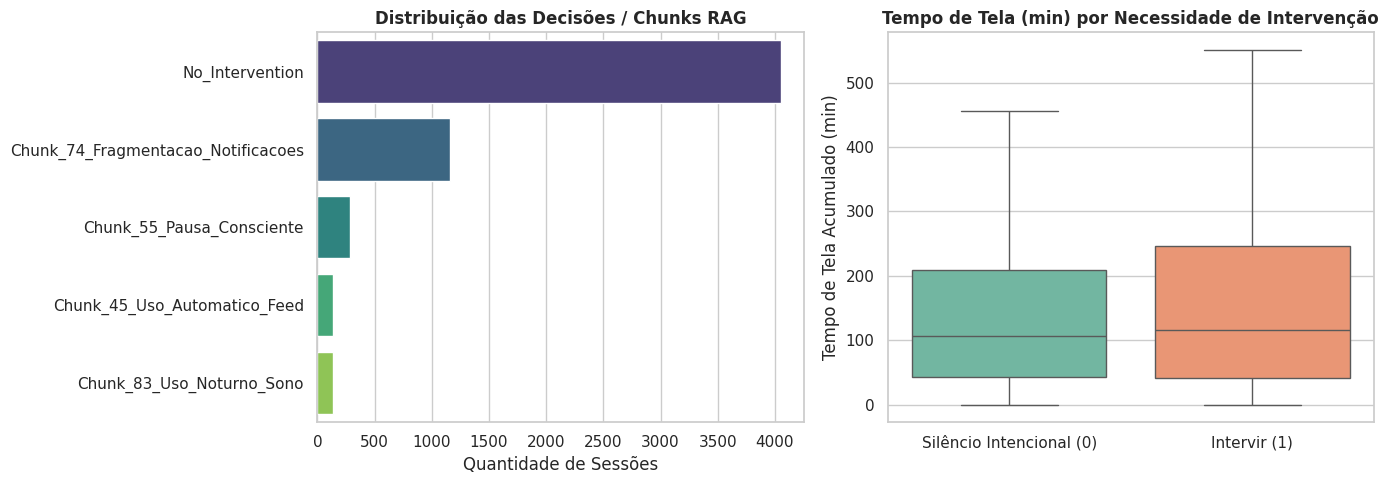

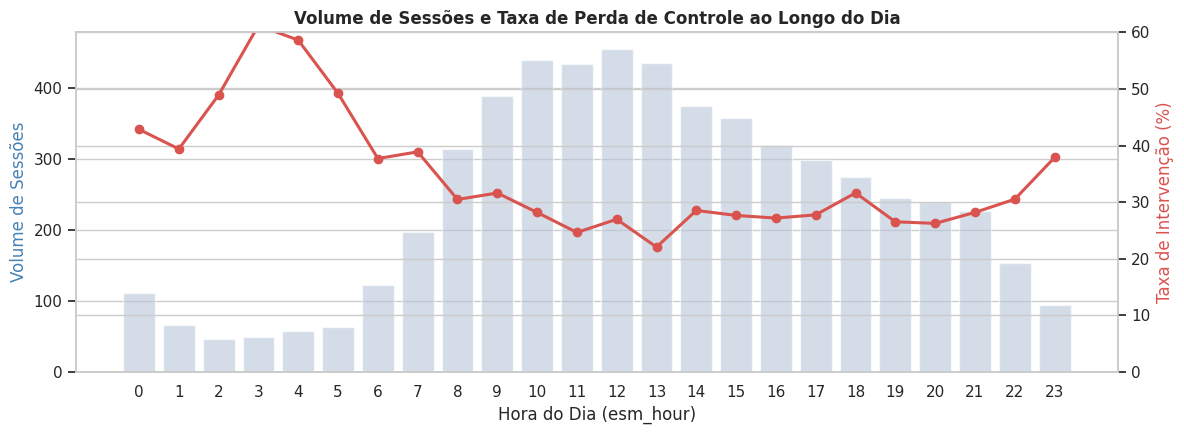

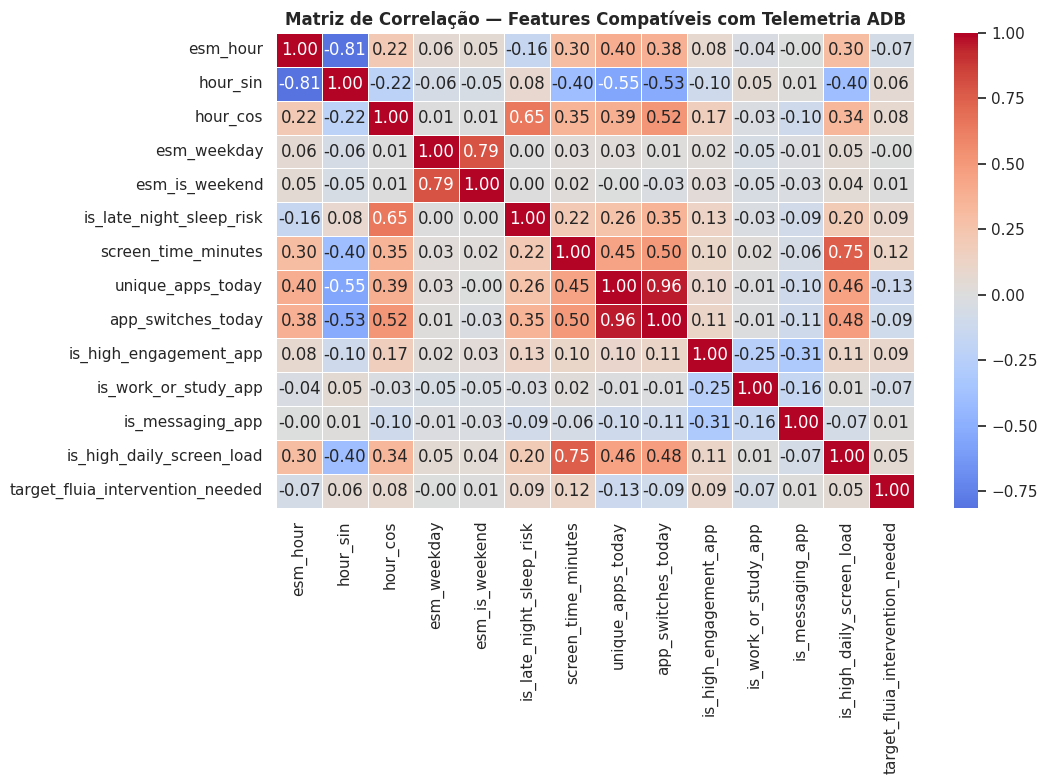

✅ EDA concluída! Gráficos salvos em: '/content/eda_fluia_plots/'


In [17]:
"""
================================================================================
FluIA — ANÁLISE EXPLORATÓRIA DE DADOS (EDA) DO DATASET ESM (5.772 SESSÕES)
================================================================================
Script completo de EDA para 'fluia_esm_engineered_features.csv' e
'app_categorization.csv', estruturado para Google Colab / Jupyter / Terminal:
  1. Diagnóstico estrutural (shape, tipos, valores ausentes, duplicados e PIDs)
  2. Estatísticas descritivas (média, desvio padrão, mediana, P25, P75, P90)
  3. Balanceamento das variáveis-alvo (Intervenção vs. Silêncio Intencional e Chunks)
  4. Padrões temporais (hora do dia, período noturno, dia útil vs. fim de semana)
  5. Análise por categoria de aplicativo e impacto na perda de controle
  6. Correlações e detecção de multicolinearidade (VIF) antes da modelagem
  7. Visualizações salvas em alta resolução (/content/eda_fluia_plots/)
================================================================================
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Configuração visual limpa
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"


def localizar_arquivo(nome_arquivo: str) -> str:
    """Busca o CSV na raiz atual, '/content/' ou '/content/sample_data/'."""
    candidatos = [
        nome_arquivo,
        os.path.join("/content", nome_arquivo),
        os.path.join("/content/sample_data", nome_arquivo),
        os.path.join("sample_data", nome_arquivo),
    ]
    for c in candidatos:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(
        f"Arquivo '{nome_arquivo}' não encontrado. Verifique se foi enviado ao diretório /content/."
    )


def executar_eda_fluia(pasta_graficos: str = "/content/eda_fluia_plots") -> dict:
    os.makedirs(pasta_graficos, exist_ok=True)

    caminho_esm = localizar_arquivo("fluia_esm_engineered_features.csv")
    df = pd.read_csv(caminho_esm)

    print("=================================================================")
    print("   1. VISÃO GERAL E INTEGRIDADE DO DATASET (FluIA ESM)           ")
    print("=================================================================")
    print(f"• Arquivo lido:         {caminho_esm}")
    print(f"• Dimensões (linhas x colunas): {df.shape[0]} sessões x {df.shape[1]} colunas")
    print(f"• Participantes únicos (pid):   {df['pid'].nunique()} usuários")
    print(f"• Sessões médias por usuário:   {df.groupby('pid').size().mean():.1f} "
          f"(mín: {df.groupby('pid').size().min()}, máx: {df.groupby('pid').size().max()})")
    print(f"• Total de valores nulos:       {int(df.isna().sum().sum())}")
    print(f"• Linhas duplicadas exatas:     {int(df.duplicated().sum())}")
    print(f"• Distribuição de tipos:\n{df.dtypes.value_counts().to_string()}\n")

    # ------------------------------------------------------------------
    # 2. ESTATÍSTICAS DESCRITIVAS DAS MÉTRICAS DE USO E AUTOCONTROLE
    # ------------------------------------------------------------------
    print("=================================================================")
    print("   2. ESTATÍSTICAS DESCRITIVAS (MÉTRICAS CHAVE DE COMPORTAMENTO)   ")
    print("=================================================================")
    metricas_chave = [
        c for c in [
            "screen_time_minutes",
            "unique_apps_today",
            "app_switches_today",
            "app_switch_rate_per_min",
            "intention_behavior_gap",
            "esm_hour"
        ] if c in df.columns
    ]
    desc = df[metricas_chave].describe(percentiles=[0.25, 0.50, 0.75, 0.90]).T
    desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "90%", "max"]]
    print(desc.round(2).to_string())
    print()

    # ------------------------------------------------------------------
    # 3. DISTRIBUIÇÃO DOS ALVOS (INTERVENÇÃO VS. SILÊNCIO INTENCIONAL)
    # ------------------------------------------------------------------
    print("=================================================================")
    print("   3. BALANCEAMENTO DOS TARGETS (DECISÃO DO AGENTE ANALISTA)    ")
    print("=================================================================")
    if "target_fluia_intervention_needed" in df.columns:
        vc_bin = df["target_fluia_intervention_needed"].value_counts()
        pct_bin = df["target_fluia_intervention_needed"].value_counts(normalize=True) * 100
        for k in vc_bin.index:
            rotulo = "Intervir (1)" if k == 1 else "Silêncio Intencional (0)"
            print(f"• {rotulo:<26}: {vc_bin[k]:4d} sessões ({pct_bin[k]:5.2f}%)")

    if "target_fluia_intervention_type" in df.columns:
        print("\nDistribuição por Tipo de Intervenção / Chunk RAG:")
        vc_tipo = df["target_fluia_intervention_type"].value_counts()
        pct_tipo = df["target_fluia_intervention_type"].value_counts(normalize=True) * 100
        for tipo in vc_tipo.index:
            print(f"  - {tipo:<36}: {vc_tipo[tipo]:4d} ({pct_tipo[tipo]:5.2f}%)")
    print()

    # ------------------------------------------------------------------
    # 4. ANÁLISE TEMPORAL E POR CATEGORIA DE APLICATIVO
    # ------------------------------------------------------------------
    print("=================================================================")
    print("   4. PADRÕES TEMPORAIS E POR CATEGORIA DE APLICATIVO            ")
    print("=================================================================")
    if "esm_is_weekend" in df.columns and "target_fluia_intervention_needed" in df.columns:
        resumo_fds = df.groupby("esm_is_weekend").agg(
            sessoes=("pid", "count"),
            taxa_intervencao=("target_fluia_intervention_needed", "mean"),
            media_tela_min=("screen_time_minutes", "mean"),
            mediana_tela_min=("screen_time_minutes", "median")
        )
        resumo_fds.index = ["Dia Útil (0)", "Fim de Semana (1)"]
        resumo_fds["taxa_intervencao"] = (resumo_fds["taxa_intervencao"] * 100).round(2)
        print("Comparativo Dia Útil vs. Fim de Semana:")
        print(resumo_fds.round(2).to_string())
        print()

    # Mapeamento das flags de categoria (genre_* ou flags funcionais)
    cols_categoria = [
        c for c in [
            "is_high_engagement_app",
            "is_work_or_study_app",
            "is_messaging_app",
            "is_late_night_sleep_risk",
            "is_quick_check_session",
            "rapid_reentry_flag"
        ] if c in df.columns
    ]
    if cols_categoria and "target_fluia_intervention_needed" in df.columns:
        print("Taxa de Intervenção quando a Flag Comportamental está Ativa (1 vs. 0):")
        linhas_flags = []
        for col in cols_categoria:
            taxa_1 = df.loc[df[col] == 1, "target_fluia_intervention_needed"].mean() * 100
            taxa_0 = df.loc[df[col] == 0, "target_fluia_intervention_needed"].mean() * 100
            qtd_1 = int((df[col] == 1).sum())
            linhas_flags.append({
                "flag": col,
                "qtd_ativa": qtd_1,
                "taxa_interv_ativa_%": round(taxa_1, 2),
                "taxa_interv_inativa_%": round(taxa_0, 2),
                "diferenca_pp": round(taxa_1 - taxa_0, 2)
            })
        df_flags = pd.DataFrame(linhas_flags).sort_values("diferenca_pp", ascending=False)
        print(df_flags.to_string(index=False))
        print()

    # ------------------------------------------------------------------
    # 5. CORRELAÇÕES E DIAGNÓSTICO DE MULTICOLINEARIDADE (VIF)
    # ------------------------------------------------------------------
    print("=================================================================")
    print("   5. TOP CORRELAÇÕES E MULTICOLINEARIDADE (VIF)                 ")
    print("=================================================================")
    cols_excluir_target = {
        "answer", "remaining_scaled", "intention_behavior_gap",
        "target_loss_of_control", "target_fluia_intervention_needed", "session_index"
    }
    num_cols = [
        c for c in df.select_dtypes(include=[np.number]).columns
        if c not in cols_excluir_target
    ]
    if "target_fluia_intervention_needed" in df.columns:
        corrs = df[num_cols].corrwith(df["target_fluia_intervention_needed"]).dropna()
        top_corrs = corrs.reindex(corrs.abs().sort_values(ascending=False).index).head(15)
        print("Top 15 Features mais correlacionadas com 'target_fluia_intervention_needed':")
        for feat, val in top_corrs.items():
            print(f"  • {feat:<32}: {val:+.4f}")

    # Cálculo de VIF nas features compatíveis com ADB
    adb_features = [
        c for c in [
            "esm_hour", "hour_sin", "hour_cos", "esm_weekday", "esm_is_weekend",
            "is_late_night_sleep_risk", "screen_time_minutes", "unique_apps_today",
            "app_switches_today", "is_high_engagement_app", "is_work_or_study_app",
            "is_messaging_app", "is_high_daily_screen_load"
        ] if c in df.columns
    ]
    if len(adb_features) > 1:
        X_vif = df[adb_features].dropna().astype(float).values
        X_const = np.column_stack([np.ones(X_vif.shape[0]), X_vif])
        vif_df = pd.DataFrame({
            "feature": adb_features,
            "VIF": [round(variance_inflation_factor(X_const, i + 1), 2) for i in range(len(adb_features))]
        }).sort_values("VIF", ascending=False)
        print("\nDiagnóstico de VIF (Features Compatíveis com Telemetria ADB):")
        print(vif_df.to_string(index=False))
        print()

    # ------------------------------------------------------------------
    # 6. GERAÇÃO E SALVAMENTO DOS GRÁFICOS DE EDA
    # ------------------------------------------------------------------
    # Gráfico 1: Distribuição dos Tipos de Intervenção + Tempo de Tela por Classe
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    if "target_fluia_intervention_type" in df.columns:
        ordem = df["target_fluia_intervention_type"].value_counts().index
        sns.countplot(data=df, y="target_fluia_intervention_type", order=ordem, ax=axes[0], palette="viridis")
        axes[0].set_title("Distribuição das Decisões / Chunks RAG")
        axes[0].set_xlabel("Quantidade de Sessões")
        axes[0].set_ylabel("")

    if "screen_time_minutes" in df.columns and "target_fluia_intervention_needed" in df.columns:
        sns.boxplot(
            data=df,
            x="target_fluia_intervention_needed",
            y="screen_time_minutes",
            showfliers=False,
            ax=axes[1],
            palette="Set2"
        )
        axes[1].set_xticklabels(["Silêncio Intencional (0)", "Intervir (1)"])
        axes[1].set_title("Tempo de Tela (min) por Necessidade de Intervenção")
        axes[1].set_xlabel("")
        axes[1].set_ylabel("Tempo de Tela Acumulado (min)")

    plt.tight_layout()
    arq_g1 = os.path.join(pasta_graficos, "eda_01_targets_e_tempo_tela.png")
    plt.savefig(arq_g1, dpi=150)
    plt.show()

    # Gráfico 2: Taxa de Intervenção e Volume por Hora do Dia
    if "esm_hour" in df.columns and "target_fluia_intervention_needed" in df.columns:
        por_hora = df.groupby("esm_hour").agg(
            taxa_intervencao=("target_fluia_intervention_needed", "mean"),
            volume=("pid", "count")
        ).reset_index()

        fig, ax1 = plt.subplots(figsize=(12, 4.5))
        sns.barplot(data=por_hora, x="esm_hour", y="volume", color="#b0c4de", alpha=0.6, ax=ax1)
        ax1.set_ylabel("Volume de Sessões", color="#4682b4")
        ax1.set_xlabel("Hora do Dia (esm_hour)")

        ax2 = ax1.twinx()
        ax2.plot(
            por_hora.index,
            por_hora["taxa_intervencao"] * 100,
            color="#d9534f",
            marker="o",
            linewidth=2.2,
            label="Taxa de Intervenção (%)"
        )
        ax2.set_ylabel("Taxa de Intervenção (%)", color="#d9534f")
        ax2.set_ylim(0, 60)
        plt.title("Volume de Sessões e Taxa de Perda de Controle ao Longo do Dia")
        plt.tight_layout()
        arq_g2 = os.path.join(pasta_graficos, "eda_02_padrao_horario.png")
        plt.savefig(arq_g2, dpi=150)
        plt.show()

    # Gráfico 3: Matriz de Correlação das Features Compatíveis com ADB
    if len(adb_features) > 1:
        plt.figure(figsize=(11, 8))
        corr_mat = df[adb_features + ["target_fluia_intervention_needed"]].corr()
        sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
        plt.title("Matriz de Correlação — Features Compatíveis com Telemetria ADB")
        plt.tight_layout()
        arq_g3 = os.path.join(pasta_graficos, "eda_03_correlacao_adb.png")
        plt.savefig(arq_g3, dpi=150)
        plt.show()

    print(f"✅ EDA concluída! Gráficos salvos em: '{pasta_graficos}/'")
    return {"dataframe": df, "estatisticas": desc}


if __name__ == "__main__":
    executar_eda_fluia()


In [15]:
#5 Agente Ação (Prescrição)
# Consultar trechos confiáveis via Tool de busca RAG.
# Redigir a proposta de sugestão acompanhada das evidências e devolvê-la ao Analista.
# não pode Ler perfil ou dados de uso.
# não pode gravar qualquer dado no sistema ou alterar metas.
# não pode enviar mensagens diretamente ao Agente Chat ou ao utilizador.
# Consulta Tool de busca RAG → Base de conhecimento (Somente Leitura)

import os
import json
from datetime import datetime, timezone
from typing import Dict, Any, List, Optional


class KnowledgeBaseRAGReadOnlyTool:
    """
    Tool de Busca RAG (Somente Leitura) — Exclusiva do #5 Agente Ação (PoLP).
    =========================================================================
    • Consulta apenas a Base de Conhecimento Científica (Chunks 44–87).
    • Não possui acesso à Base de Perfil, histórico de telemetria nem check-ins.
    • Não realiza operações de escrita/alteração em nenhuma base.
    """

    # Base de conhecimento científica estruturada (Chunks 44–87)
    _KNOWLEDGE_BASE_CHUNKS: Dict[str, Dict[str, Any]] = {
        "44": {
            "chunk_id": "44",
            "category": "Uso automático",
            "title": "Fricção Intencional e Quebra de Hábito Automático",
            "evidence_summary": (
                "Pequenas barreiras de atrito no ambiente digital interrompem o ciclo automático "
                "de abertura compulsiva de feeds infinitos sem exigir força de vontade contínua."
            ),
            "clinical_guideline": (
                "Sugerir ativação de escala de cinza durante períodos de descanso ou, caso o usuário "
                "necessite de tela colorida, propor micro-pausas ativas temporizadas."
            ),
            "contraindications": ["needs_color_screen (para escala de cinza)"]
        },
        "45": {
            "chunk_id": "45",
            "category": "Uso automático",
            "title": "Substituição Comportamental por Pausas Ativas",
            "evidence_summary": (
                "Alternar blocos de uso passivo de tela com pausas físicas breves (5 a 20 minutos de "
                "caminhada ou alongamento) reduz fadiga cognitiva e melhora a autorregulação."
            ),
            "clinical_guideline": (
                "Recomendar substituição gradual de sessões passivas prolongadas por caminhada leve "
                "ou alongamento ativo, respeitando a rotina laboral do usuário."
            ),
            "contraindications": []
        },
        "55": {
            "chunk_id": "55",
            "category": "Uso automático",
            "title": "Regulação de Sessões e Temporizadores Conscientes",
            "evidence_summary": (
                "Definir limites temporais explícitos antes de iniciar entretenimento digital reduz "
                "a lacuna entre intenção de uso e tempo real gasto."
            ),
            "clinical_guideline": (
                "Propor definição prévia de janela de tempo (ex.: 20–30 min) com lembrete suave de encerramento."
            ),
            "contraindications": []
        },
        "74": {
            "chunk_id": "74",
            "category": "Notificações",
            "title": "Gestão Seletiva de Interrupções e Lotes de Notificação",
            "evidence_summary": (
                "Interrupções frequentes fragmentam a atenção e aumentam desbloqueios reativos. "
                "Agrupar ou silenciar alertas não essenciais preserva o foco sem comprometer canais críticos."
            ),
            "clinical_guideline": (
                "Silenciar notificações promocionais/de navegadores e manter apenas chamadas ou contatos "
                "prioritários quando o aparelho precisa permanecer acessível para trabalho ou cuidado."
            ),
            "contraindications": ["modo avião ou desligamento total se needs_phone_reachable_for_care_or_work=True"]
        },
        "83": {
            "chunk_id": "83",
            "category": "Uso noturno",
            "title": "Higiene do Sono e Ritual de Transição Noturna",
            "evidence_summary": (
                "A exposição a estímulos audiovisuais interativos e luz de tela nos 45 a 60 minutos "
                "anteriores ao horário alvo de dormir atrasa a latência do sono e reduz a disposição matinal."
            ),
            "clinical_guideline": (
                "Estabelecer desaceleração digital 45 minutos antes do horário de dormir, reduzindo brilho "
                "e silenciando alertas recreativos sem bloquear chamadas urgentes de trabalho/cuidado."
            ),
            "contraindications": ["desligar aparelho se needs_phone_reachable_for_care_or_work=True"]
        },
        "87": {
            "chunk_id": "87",
            "category": "Segurança",
            "title": "Protocolo de Acolhimento e Encaminhamento em Sofrimento Emocional Persistente",
            "evidence_summary": (
                "Sinais de tristeza, ansiedade ou esgotamento intenso e persistente exigem acolhimento "
                "empático imediato, abstenção de diagnóstico automatizado e encaminhamento à rede de saúde."
            ),
            "clinical_guideline": (
                "Acolher sem julgamento, não formular diagnóstico médico e orientar procura por "
                "profissional de saúde (UBS ou CAPS) e apoio gratuito 24h pelo CVV (telefone 188)."
            ),
            "contraindications": []
        }
    }

    def buscar_trechos_confiaveis(
        self,
        target_category: str,
        rag_query_intent: Optional[str] = None,
        top_k: int = 2
    ) -> List[Dict[str, Any]]:
        """
        Consulta somente leitura na Base de Conhecimento Científica (Chunks 44–87).
        Prioriza obrigatoriamente o Chunk 87 quando a categoria for 'Segurança'.
        """
        if target_category == "Segurança":
            return [dict(self._KNOWLEDGE_BASE_CHUNKS["87"])]

        candidatos = [
            dict(chunk)
            for chunk in self._KNOWLEDGE_BASE_CHUNKS.values()
            if chunk["category"].lower() == target_category.lower()
        ]

        # Ranqueamento léxico leve caso exista intenção de busca detalhada
        if rag_query_intent and len(candidatos) > 1:
            termos = set(rag_query_intent.lower().split())
            candidatos.sort(
                key=lambda c: sum(
                    1 for t in termos
                    if t in (c["title"] + " " + c["evidence_summary"] + " " + c["clinical_guideline"]).lower()
                ),
                reverse=True
            )

        if not candidatos:
            candidatos = [dict(self._KNOWLEDGE_BASE_CHUNKS["45"])]

        return candidatos[:top_k]


class AgenteAcaoPrescricaoFluIA:
    """
    ETAPA #5 — AGENTE AÇÃO (Prescrição Baseada em Evidências Científicas)
    ===========================================================================
    PERMISSÕES (PoLP):
      [OK] Receber exclusivamente o Contrato 2 enviado pelo Agente Analista
      [OK] Consultar trechos confiáveis via Tool de busca RAG (Somente Leitura)
      [OK] Redigir proposta de sugestão acompanhada das evidências (Contrato 3)
      [OK] Devolver a proposta exclusivamente ao Agente Analista (Juiz)

    RESTRIÇÕES ESTRITAS (BLOQUEADAS):
      [X] NÃO lê Base de Perfil, logs de telemetria nem check-ins brutos
      [X] NÃO grava qualquer arquivo em disco nem altera metas do usuário
      [X] NÃO envia mensagens diretamente ao Agente Chat ou ao utilizador
    """

    def __init__(self):
        self.rag_tool = KnowledgeBaseRAGReadOnlyTool()

    def _validar_isolamento_entrada(self, contrato_2: Dict[str, Any]):
        """Garante que o Agente Ação opere apenas sobre o Contrato 2 do Analista."""
        if contrato_2.get("event_type") != "analyst_enriched_context":
            raise PermissionError(
                "[VIOLAÇÃO PoLP] O Agente Ação aceita exclusivamente o Contrato 2 "
                "('analyst_enriched_context') emitido pelo Agente Analista."
            )

    def _redigir_mensagem_com_restricoes(
        self,
        nome_usuario: str,
        categoria: str,
        restricoes: Dict[str, Any],
        snapshot: Dict[str, Any],
        trecho_principal: Dict[str, Any]
    ) -> str:
        """
        Redige a sugestão personalizada respeitando as restrições rígidas enviadas no Contrato 2
        (ex.: needs_color_screen e needs_phone_reachable_for_care_or_work).
        """
        precisa_tela_cor = bool(restricoes.get("needs_color_screen", False))
        precisa_celular_acessivel = bool(restricoes.get("needs_phone_reachable_for_care_or_work", True))
        horario_dormir = restricoes.get("bedtime_target", "22:30")

        if categoria == "Segurança":
            return (
                f"{nome_usuario}, percebi pelo seu relato que os últimos dias têm sido emocionalmente pesados. "
                "Você não precisa passar por isso sozinho: considere buscar apoio com um profissional de saúde "
                "na UBS ou CAPS mais próximo, ou entrar em contato gratuitamente com o CVV pelo telefone 188 (atendimento 24h)."
            )

        if categoria == "Uso noturno":
            min_noturno = snapshot.get("night_19h_23h_min", 0)
            clausula_acessibilidade = (
                "mantendo seu aparelho acessível para chamadas importantes de trabalho ou cuidado"
                if precisa_celular_acessivel
                else "reduzindo estímulos de tela antes de deitar"
            )
            return (
                f"Olá, {nome_usuario}! Notei que houve {min_noturno} min de uso recreativo entre 19h e 23h. "
                f"Para apoiar sua meta de dormir perto das {horario_dormir} {clausula_acessibilidade}, "
                "experimente silenciar apenas notificações de entretenimento 45 minutos antes de deitar e "
                "priorizar uma atividade relaxante fora da tela."
            )

        if categoria == "Notificações":
            total_notif = snapshot.get("notifications", 0)
            clausula_trabalho = (
                "preservando alertas essenciais de trabalho e chamadas"
                if precisa_celular_acessivel
                else "liberando blocos de foco contínuo"
            )
            return (
                f"Olá, {nome_usuario}! Seu celular registrou {total_notif} notificações no período. "
                f"Silenciar alertas promocionais de navegadores e aplicativos não prioritários ajuda a reduzir "
                f"interrupções {clausula_trabalho}."
            )

        # Categoria padrão: 'Uso automático'
        if precisa_tela_cor:
            return (
                f"Olá, {nome_usuario}! Para interromper o uso automático de telas mantendo a tela colorida "
                "para suas atividades, experimente definir um temporizador de 20 minutos seguido de uma pausa "
                "breve de 5 a 15 minutos para alongamento ou caminhada leve."
            )

        return (
            f"Olá, {nome_usuario}! Para quebrar o ciclo de uso automático de telas e renovar sua energia, "
            "experimente ativar a escala de cinza nos momentos de descanso e realizar uma caminhada leve "
            "de 15 a 20 minutos hoje."
        )

    def prescrever_proposta_para_analista(self, contrato_2: Dict[str, Any]) -> Dict[str, Any]:
        """
        Executa a prescrição baseada em evidências:
          1. Valida que a entrada veio do Agente Analista (Contrato 2).
          2. Caso intervention_needed == False, devolve proposta nula (respeito ao silêncio).
          3. Consulta trechos confiáveis via Tool RAG (Somente Leitura).
          4. Redige a proposta acompanhada das evidências científicas e devolve ao Analista (Contrato 3).
          5. NÃO salva arquivos em disco e NÃO fala com o Chat/usuário.
        """
        self._validar_isolamento_entrada(contrato_2)

        decisao = contrato_2.get("analysis_decision", {})
        user_ctx = contrato_2.get("user_context", {})
        data_ref = contrato_2.get("reference_date", datetime.now().strftime("%Y-%m-%d"))
        user_id = contrato_2.get("user_id", "usr_padrao_01")
        nome_usuario = user_ctx.get("name", "Usuário")

        precisa_intervir = bool(decisao.get("intervention_needed", False))
        categoria = decisao.get("target_category", "Nenhuma")
        query_intent = decisao.get("rag_query_intent")

        # Caso de Silêncio Intencional
        if not precisa_intervir:
            contrato_3_silencio = {
                "contract_version": "1.1",
                "event_type": "action_proposed_intervention",
                "recipient_agent": "AgenteAnalista",
                "reference_date": data_ref,
                "timestamp": datetime.now(timezone.utc).isoformat(),
                "user_id": user_id,
                "intervention_id": f"int_{data_ref.replace('-', '')}_silent",
                "source_chunk_id": None,
                "retrieved_evidences": [],
                "proposed_message": None
            }
            print("=================================================================")
            print("   #5 AGENTE AÇÃO (PRESCRIÇÃO) — SILÊNCIO INTENCIONAL            ")
            print("=================================================================")
            print("• Nenhuma intervenção necessária. Devolvendo Contrato 3 vazio ao Analista.\n")
            return contrato_3_silencio

        # Consulta Tool de Busca RAG (Somente Leitura)
        evidencias_rag = self.rag_tool.buscar_trechos_confiaveis(
            target_category=categoria,
            rag_query_intent=query_intent,
            top_k=2
        )
        trecho_principal = evidencias_rag[0]

        mensagem_proposta = self._redigir_mensagem_com_restricoes(
            nome_usuario=nome_usuario,
            categoria=categoria,
            restricoes=user_ctx.get("hard_constraints", {}),
            snapshot=decisao.get("metrics_snapshot", {}),
            trecho_principal=trecho_principal
        )

        # Contrato 3 devolvido exclusivamente em memória para o Agente Analista (Juiz)
        contrato_3_proposta = {
            "contract_version": "1.1",
            "event_type": "action_proposed_intervention",
            "recipient_agent": "AgenteAnalista",
            "reference_date": data_ref,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "user_id": user_id,
            "intervention_id": f"int_{data_ref.replace('-', '')}_01",
            "target_category": categoria,
            "source_chunk_id": trecho_principal["chunk_id"],
            "retrieved_evidences": [
                {
                    "chunk_id": ev["chunk_id"],
                    "title": ev["title"],
                    "evidence_summary": ev["evidence_summary"],
                    "clinical_guideline": ev["clinical_guideline"]
                }
                for ev in evidencias_rag
            ],
            "proposed_message": mensagem_proposta
        }

        print("=================================================================")
        print("   #5 AGENTE AÇÃO (PRESCRIÇÃO) — PROPOSTA ENVIADA AO ANALISTA    ")
        print("=================================================================")
        print(f"• Destinatário exclusivo: {contrato_3_proposta['recipient_agent']} (Juiz)")
        print(f"• Categoria alvo:         {categoria}")
        print(f"• Chunk principal RAG:    #{trecho_principal['chunk_id']} — {trecho_principal['title']}")
        print(f"• Evidências anexadas:    {[ev['chunk_id'] for ev in evidencias_rag]}")
        print("• Gravação em disco:      Nenhuma (PoLP estrito)")
        print("• Comunicação externa:    Bloqueada (aguardando veredito do Juiz)\n")

        return contrato_3_proposta


# ==============================================================================
# TESTE ISOLADO DA ETAPA #5 (RECEBENDO CONTRATO 2 DO ANALISTA)
# ==============================================================================
if __name__ == "__main__":
    # Simulação do Contrato 2 emitido pelo Agente Analista (sem acesso direto a bases)
    contrato_2_exemplo = {
        "contract_version": "1.1",
        "event_type": "analyst_enriched_context",
        "reference_date": "2026-11-24",
        "user_id": "usr_participante_01",
        "user_context": {
            "name": "Participante",
            "communication_tone": "empatico",
            "hard_constraints": {
                "needs_color_screen": False,
                "needs_phone_reachable_for_care_or_work": True,
                "bedtime_target": "22:30"
            }
        },
        "analysis_decision": {
            "intervention_needed": True,
            "severity": "alta",
            "target_category": "Uso noturno",
            "rag_query_intent": "higiene do sono uso noturno de telas antes de dormir",
            "metrics_snapshot": {
                "night_19h_23h_min": 81.0,
                "leisure_min": 128.78,
                "notifications": 115,
                "unlocks": 23
            }
        }
    }

    agente_acao = AgenteAcaoPrescricaoFluIA()
    contrato_3_gerado = agente_acao.prescrever_proposta_para_analista(contrato_2_exemplo)
    print(json.dumps(contrato_3_gerado, indent=2, ensure_ascii=False))



   #5 AGENTE AÇÃO (PRESCRIÇÃO) — PROPOSTA ENVIADA AO ANALISTA    
• Destinatário exclusivo: AgenteAnalista (Juiz)
• Categoria alvo:         Uso noturno
• Chunk principal RAG:    #83 — Higiene do Sono e Ritual de Transição Noturna
• Evidências anexadas:    ['83']
• Gravação em disco:      Nenhuma (PoLP estrito)
• Comunicação externa:    Bloqueada (aguardando veredito do Juiz)

{
  "contract_version": "1.1",
  "event_type": "action_proposed_intervention",
  "recipient_agent": "AgenteAnalista",
  "reference_date": "2026-11-24",
  "timestamp": "2026-11-24T20:15:57.478872+00:00",
  "user_id": "usr_participante_01",
  "intervention_id": "int_20261124_01",
  "target_category": "Uso noturno",
  "source_chunk_id": "83",
  "retrieved_evidences": [
    {
      "chunk_id": "83",
      "title": "Higiene do Sono e Ritual de Transição Noturna",
      "evidence_summary": "A exposição a estímulos audiovisuais interativos e luz de tela nos 45 a 60 minutos anteriores ao horário alvo de dormir atrasa a la

In [18]:
#6 apresentação de notificação de usuario apos analise do analista
import os
import glob
import json
from datetime import datetime, timezone
from typing import Optional, Dict, Any

try:
    from IPython.display import display, HTML
    IN_NOTEBOOK = True
except ImportError:
    IN_NOTEBOOK = False


def carregar_contrato_json(pasta: str, prefixo: str, data_referencia: Optional[str] = None) -> Dict[str, Any]:
    """Lê o contrato JSON mais recente (ou da data especificada) emitido pelo Agente Analista."""
    if not os.path.isdir(pasta):
        raise FileNotFoundError(f"Diretório '{pasta}' não encontrado. Execute as etapas anteriores primeiro.")

    if data_referencia:
        caminho = os.path.join(pasta, f"{prefixo}_{data_referencia}.json")
        if os.path.exists(caminho):
            with open(caminho, "r", encoding="utf-8") as f:
                return json.load(f)

    arquivos = sorted(glob.glob(os.path.join(pasta, f"{prefixo}_*.json")))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum arquivo '{prefixo}_*.json' encontrado em '{pasta}'.")

    with open(arquivos[-1], "r", encoding="utf-8") as f:
        return json.load(f)


def apresentar_notificacao_analista(
    pasta_analista: str = "/content/contratos_analista",
    data_referencia: Optional[str] = None,
    contrato_2_direto: Optional[Dict[str, Any]] = None,
    contrato_4_direto: Optional[Dict[str, Any]] = None
) -> Dict[str, Any]:
    """
    Apresenta a notificação visual e estruturada da análise do #4 Agente Analista
    (Contrato 2 — Contexto Enriquecido + Contrato 4 — Veredito do Juiz),
    respeitando o Silêncio Intencional e a separação PoLP (encaminhando a entrega
    final exclusivamente para o #3 Agente Chat).
    """
    c2 = contrato_2_direto or carregar_contrato_json(pasta_analista, "analyst_context_contract_2", data_referencia)
    data_ref = c2.get("reference_date", datetime.now().strftime("%Y-%m-%d"))

    try:
        c4 = contrato_4_direto or carregar_contrato_json(pasta_analista, "validated_for_chat_contract_4", data_ref)
    except FileNotFoundError:
        c4 = {
            "judge_verdict": "pending_action_agent",
            "delivery_status": "awaiting_validation",
            "validated_user_message": None,
            "audit_notes": ["Aguardando proposta do #5 Agente Ação para auditoria final."]
        }

    user_ctx = c2.get("user_context", {})
    decisao = c2.get("analysis_decision", {})
    snap = decisao.get("metrics_snapshot", {})
    ml_info = snap.get("ml_calibrated_inference", {})

    nome_usuario = user_ctx.get("name", "Usuário")
    precisa_intervir = bool(decisao.get("intervention_needed", False))
    severidade = decisao.get("severity", "baixa").upper()
    categoria = decisao.get("target_category", "Nenhuma")
    justificativa = decisao.get("diagnostic_reasoning", "")

    veredito_juiz = c4.get("judge_verdict", "N/A").upper()
    status_entrega = c4.get("delivery_status", "silent_no_action")
    msg_validada = c4.get("validated_user_message")
    chunk_origem = c4.get("source_chunk_id")

    # Define paleta visual e ícone de acordo com a severidade/silêncio
    if not precisa_intervir or status_entrega == "silent_no_action":
        cor_borda = "#2e7d32"
        cor_fundo = "#f1f8e9"
        icone = "🔇"
        titulo_notif = f"FluIA — Silêncio Intencional Ativado ({data_ref})"
        subtitulo_status = "Equilíbrio dentro das metas • Nenhuma intervenção disparada"
    elif categoria == "Segurança":
        cor_borda = "#c62828"
        cor_fundo = "#ffebee"
        icone = "🆘"
        titulo_notif = f"FluIA — Alerta Prioritário de Bem-Estar ({data_ref})"
        subtitulo_status = f"Severidade: {severidade} • Protocolo Chunk 87"
    else:
        cor_borda = "#ef6c00" if severidade == "ALTA" else "#1565c0"
        cor_fundo = "#fff3e0" if severidade == "ALTA" else "#e3f2fd"
        icone = "🔔"
        titulo_notif = f"FluIA — Análise Comportamental & Recomendação ({data_ref})"
        subtitulo_status = f"Categoria: {categoria} • Severidade: {severidade}"

    risco_ml_txt = (
        f"{ml_info['calibrated_risk_probability']:.1%} (Limiar: {ml_info.get('decision_threshold', 0.30):.0%})"
        if "calibrated_risk_probability" in ml_info
        else "N/A"
    )

    # 1. Exibição em Card HTML rico (Google Colab / Jupyter)
    if IN_NOTEBOOK:
        bloco_mensagem_html = ""
        if status_entrega == "ready_to_deliver" and msg_validada:
            bloco_mensagem_html = f"""
            <div style="margin-top:12px; padding:12px; background:#ffffff; border-left:4px solid {cor_borda}; border-radius:6px;">
                <div style="font-size:12px; color:#555; font-weight:bold; margin-bottom:4px;">
                    💬 MENSAGEM VALIDADA PELO JUIZ (ENCAMINHADA AO AGENTE CHAT • CHUNK #{chunk_origem}):
                </div>
                <div style="font-size:14px; color:#111; line-height:1.45;">"{msg_validada}"</div>
            </div>
            """
        else:
            bloco_mensagem_html = """
            <div style="margin-top:10px; font-size:13px; color:#33691e;">
                ✅ <b>Silêncio Intencional respeitado:</b> Nenhuma notificação intrusiva enviada ao utilizador.
            </div>
            """

        html_card = f"""
        <div style="font-family: 'Segoe UI', Arial, sans-serif; border: 2px solid {cor_borda}; background: {cor_fundo};
                    border-radius: 10px; padding: 16px; max-width: 760px; margin: 10px 0; box-shadow: 0 2px 6px rgba(0,0,0,0.08);">
            <div style="display:flex; justify-content:space-between; align-items:center; border-bottom:1px solid rgba(0,0,0,0.1); padding-bottom:8px;">
                <div>
                    <span style="font-size:20px;">{icone}</span>
                    <strong style="font-size:16px; color:#1a1a1a;"> {titulo_notif}</strong>
                    <div style="font-size:12px; color:#444; margin-top:2px;">Utilizador: <b>{nome_usuario}</b> | {subtitulo_status}</div>
                </div>
                <span style="background:{cor_borda}; color:#fff; padding:4px 10px; border-radius:12px; font-size:11px; font-weight:bold;">
                    JUIZ: {veredito_juiz}
                </span>
            </div>

            <div style="margin-top:10px; font-size:13.5px; color:#222;">
                <b>Diagnóstico do Agente Analista:</b> {justificativa}
            </div>

            <div style="display:grid; grid-template-columns: repeat(4, 1fr); gap:8px; margin-top:12px; text-align:center;">
                <div style="background:#fff; padding:8px; border-radius:6px; border:1px solid #ddd;">
                    <div style="font-size:11px; color:#666;">Uso Lazer</div>
                    <div style="font-size:14px; font-weight:bold; color:#111;">{snap.get('leisure_min', 0)} min</div>
                </div>
                <div style="background:#fff; padding:8px; border-radius:6px; border:1px solid #ddd;">
                    <div style="font-size:11px; color:#666;">Janela 19h–23h</div>
                    <div style="font-size:14px; font-weight:bold; color:#111;">{snap.get('night_19h_23h_min', 0)} min</div>
                </div>
                <div style="background:#fff; padding:8px; border-radius:6px; border:1px solid #ddd;">
                    <div style="font-size:11px; color:#666;">Notificações / Desbl.</div>
                    <div style="font-size:14px; font-weight:bold; color:#111;">{snap.get('notifications', 0)} / {snap.get('unlocks', 0)}</div>
                </div>
                <div style="background:#fff; padding:8px; border-radius:6px; border:1px solid #ddd;">
                    <div style="font-size:11px; color:#666;">Risco ML Calibrado</div>
                    <div style="font-size:14px; font-weight:bold; color:{cor_borda};">{risco_ml_txt}</div>
                </div>
            </div>

            {bloco_mensagem_html}
        </div>
        """
        display(HTML(html_card))

    # 2. Exibição limpa em Console / Terminal (sempre executada para logs e auditoria)
    print("=================================================================")
    print(f" {icone} {titulo_notif}")
    print("=================================================================")
    print(f"Utilizador:         {nome_usuario}")
    print(f"Status / Veredito:  {subtitulo_status} | Juiz: {veredito_juiz}")
    print(f"Métricas do Dia:    Lazer={snap.get('leisure_min', 0)} min | Noturno(19h-23h)={snap.get('night_19h_23h_min', 0)} min | "
          f"Notif={snap.get('notifications', 0)} | Desbl={snap.get('unlocks', 0)}")
    print(f"Risco ML Calibrado: {risco_ml_txt}")
    print(f"Diagnóstico:        {justificativa}")
    print("-" * 65)
    if status_entrega == "ready_to_deliver" and msg_validada:
        print(f"💬 Notificação Validada (Chunk #{chunk_origem} -> Agente Chat):")
        print(f"   \"{msg_validada}\"")
    else:
        print("🔇 Silêncio Intencional: Nenhuma mensagem enviada ao utilizador.")
    print("=================================================================\n")

    return {
        "reference_date": data_ref,
        "user_name": nome_usuario,
        "intervention_needed": precisa_intervir,
        "target_category": categoria,
        "judge_verdict": veredito_juiz,
        "delivery_status": status_entrega,
        "validated_user_message": msg_validada
    }


# =====================================================================
# EXECUÇÃO DIRETA (LÊ OS CONTRATOS DO ANALISTA OU EXECUTA DEMONSTRAÇÃO)
# =====================================================================
if __name__ == "__main__":
    try:
        apresentar_notificacao_analista()
    except FileNotFoundError:
        # Demonstração imediata caso os JSONs ainda não tenham sido gerados na sessão atual
        c2_demo = {
            "reference_date": "2026-11-24",
            "user_context": {"name": "Participante"},
            "analysis_decision": {
                "intervention_needed": True,
                "severity": "alta",
                "target_category": "Uso noturno",
                "diagnostic_reasoning": "Uso recreativo noturno (19h–23h) atingiu 81.0 min (baseline: 45.0 min), impactando a meta de sono (22:30).",
                "metrics_snapshot": {
                    "leisure_min": 128.78,
                    "night_19h_23h_min": 81.0,
                    "notifications": 115,
                    "unlocks": 23,
                    "ml_calibrated_inference": {
                        "calibrated_risk_probability": 0.412,
                        "decision_threshold": 0.30
                    }
                }
            }
        }
        c4_demo = {
            "judge_verdict": "approved",
            "delivery_status": "ready_to_deliver",
            "source_chunk_id": "83",
            "validated_user_message": (
                "Olá, Participante! Notei que houve 81.0 min de uso recreativo entre 19h e 23h. "
                "Para apoiar sua meta de dormir perto das 22:30 mantendo seu aparelho acessível para chamadas importantes de trabalho ou cuidado, "
                "experimente silenciar apenas notificações de entretenimento 45 minutos antes de deitar."
            )
        }
        apresentar_notificacao_analista(contrato_2_direto=c2_demo, contrato_4_direto=c4_demo)

 🔔 FluIA — Análise Comportamental & Recomendação (2026-11-24)
Utilizador:         higor
Status / Veredito:  Categoria: Uso noturno • Severidade: MEDIA | Juiz: APPROVED
Métricas do Dia:    Lazer=210.93 min | Noturno(19h-23h)=39.7 min | Notif=96 | Desbl=22
Risco ML Calibrado: 64.8% (Limiar: 30%)
Diagnóstico:        Uso recreativo noturno (19h–23h) atingiu 39.7 min (baseline [historico_individual]: 81.0 min; risco ML calibrado: 64.8%), impactando a meta de sono (22:30). Principais apps: com.android.chrome [Others] (62.5 min), com.sec.android.app.sbrowser [Others] (35.58 min), com.google.android.googlequicksearchbox [Others] (30.25 min).
-----------------------------------------------------------------
💬 Notificação Validada (Chunk #83 -> Agente Chat):
   "Olá, higor! Notei que ontem houve uso recreativo elevado no período noturno. Para proteger sua meta de dormir perto das 22:30 mantendo seu celular acessível para trabalho, experimente silenciar apenas notificações recreativas 45 minutos 